<a href="https://colab.research.google.com/github/LielUziahu/S_Pistillata_Bet-Hedging/blob/main/Spat_Physiology.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Global Styling & Setup
Imports the required data science packages and sets the visual fingerprint (fonts, colors, and line weights) so the final plot perfectly matches previous  figures.

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- GLOBAL PLOT STYLING ---
plt.rcParams.update({
    "font.family": "Serif",
    "font.size": 14,          # Global text size
    "axes.titlesize": 16,     # Plot titles
    "axes.titleweight": "bold", # Global title fontweight
    "axes.titlepad": 20,      # Global title padding
    "axes.labelsize": 12,     # Axis labels
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.edgecolor": "black",
    "axes.linewidth": 1.2,
    "svg.fonttype": "none" # Protects text vectors for journal export
})
sns.set_theme(style="white", font="serif")

# --- GLOBAL COLOR PALETTE & PLOT ARTIFACTS ---
variant_colors = {'HF': '#2ca02c', 'NF': '#d62728'}

sub_condition_plot_order = [
    'Ambient \n(23°C, pH 8.2, 10m)',
    '27°C',
    '32°C',
    'pH 7.8',
    'pH 7.6',
    '50m',
    'Dark',
]

global_fig_size = (10, 6)
global_jitter = 0.1
global_marker_size = 5
global_alpha = 0.6
# Centralized Asterisk Settings - UPDATED to smaller size
global_asterisk_size = 12
global_asterisk_weight = 'bold'

# Added for cleaner look
global_y_nbins = 3

print(f"Global styling initialized. Asterisk size reduced to {global_asterisk_size}.")

Global styling initialized. Asterisk size reduced to 12.


# Settlment


## Block 1: Data Loading, Cleaning, and Phenotype Filtering.
In this block, we standardize the column names and morph labels from your four different CSV files, remove the "Partial Fluorescent" (PF) data as requested by your PI, and merge them into a single "Master" dataset for analysis.

In [62]:
import pandas as pd
import numpy as np

# --- HELPER FUNCTION ---
def clean_morph(val):
    """Standardizes morph labels and handles typos/extra spaces."""
    val = str(val).strip().lower()
    if 'high' in val or 'hf' == val:
        return 'HF'
    if 'no' in val or 'nf' == val:
        return 'NF'
    if 'partial' in val or 'pf' == val:
        return 'PF'
    return None

# ==========================================
# BLOCK 1: LOADING & STANDARDIZING DATA
# ==========================================

# 1. Load Ambient (Control)
df_amb = pd.read_csv("Settlment_Ambient.csv")
df_amb['morph'] = df_amb['Varient'].apply(clean_morph)

# Safely rename and avoid creating duplicate 'settlement' columns
if 'Settled' in df_amb.columns:
    df_amb = df_amb.rename(columns={'Settled': 'settlement'})
elif 'setteled %' in df_amb.columns:
    df_amb = df_amb.rename(columns={'setteled %': 'settlement'})

# Force unique column names in case duplicates exist
df_amb = df_amb.loc[:, ~df_amb.columns.duplicated()]
df_amb = df_amb[['morph', 'settlement']].copy()
df_amb['Treatment'] = 'Ambient'

# 2. Load Depth (Light) - Filtering for 50m and Dark
df_depth = pd.read_csv("Settlement_Depth.csv")
df_depth['morph'] = df_depth['fluorescense level'].apply(clean_morph)
if 'setteled %' in df_depth.columns:
    df_depth['settlement'] = pd.to_numeric(df_depth['setteled %'], errors='coerce')
else:
    df_depth['settlement'] = pd.to_numeric(df_depth['Settled'], errors='coerce', default=np.nan)
# We exclude '10m' here because it is covered by the 'Ambient' control
df_depth = df_depth[df_depth['Light'].astype(str).str.upper().isin(['50M', 'DARK'])].copy()
df_depth['Treatment'] = df_depth['Light'].str.capitalize()

# 3. Load pH Stress
df_ph = pd.read_csv("Settlement_pH.csv")
df_ph['morph'] = df_ph['fluorescense level'].apply(clean_morph)
df_ph['settlement'] = pd.to_numeric(df_ph['setteled %'], errors='coerce')
df_ph = df_ph[df_ph['pH'].astype(str).isin(['7.8', '7.6'])].copy()
df_ph['Treatment'] = 'pH ' + df_ph['pH'].astype(str)

# 4. Load Thermal Stress
df_temp = pd.read_csv("Settlement_Temp.csv")
df_temp['morph'] = df_temp['fluorescense level'].apply(clean_morph)
df_temp['settlement'] = pd.to_numeric(df_temp['setteled %'], errors='coerce')
df_temp = df_temp[df_temp['Temp'].astype(float).isin([27, 32])].copy()
df_temp['Treatment'] = df_temp['Temp'].astype(float).astype(int).astype(str) + '°C'

# 5. Combine all into Master DataFrame and REMOVE 'PF'
master_df = pd.concat([
    df_amb[['morph', 'settlement', 'Treatment']],
    df_depth[['morph', 'settlement', 'Treatment']],
    df_ph[['morph', 'settlement', 'Treatment']],
    df_temp[['morph', 'settlement', 'Treatment']]
], ignore_index=True)

# Final Cleaning: Drop rows with missing values and remove the PF morph
master_df = master_df.dropna(subset=['morph', 'settlement'])
master_df = master_df[master_df['morph'] != 'PF'].copy()

# Reset index to ensure unique indices for later outlier identification
master_df = master_df.reset_index(drop=True)
# Add a unique identifier column to track rows robustly
master_df['original_idx'] = master_df.index

print(f"Block 1 Complete.")
print(f"Total observations: {len(master_df)}")
print(f"Morphs remaining: {master_df['morph'].unique()}")
print(f"Treatments loaded: {master_df['Treatment'].unique().tolist()}")
print(master_df.head())

Block 1 Complete.
Total observations: 126
Morphs remaining: ['NF' 'HF']
Treatments loaded: ['Ambient', '50m', 'Dark', 'pH 7.8', 'pH 7.6', '27°C', '32°C']
  morph  settlement Treatment  original_idx
0    NF           3   Ambient             0
1    NF           7   Ambient             1
2    NF           3   Ambient             2
3    NF           2   Ambient             3
4    NF           7   Ambient             4


## Block 2: Outlier Removal via 1.5*IQR.
This block ensures that technical "noise" or extreme values don't skew your final results. We perform this calculation separately for each group (e.g., HF in Ambient vs. NF in Ambient) to account for the natural variance within each phenotype.

In [63]:
import pandas as pd
import numpy as np

# ==========================================
# BLOCK 2: OUTLIER REMOVAL (1.5 * IQR) - MODIFIED TO SKIP FOR SETTLEMENT DATA
# ==========================================

# The user has requested to skip 1.5 * IQR outlier removal for Settlement data.
# Therefore, master_df_clean will be a direct copy of master_df.
master_df_clean = master_df.copy()

# Since no outliers are being removed for settlement data, set removed_count to 0.
removed_count = 0
count_after = len(master_df_clean)

print("Block 2 Complete.")
print(f"Outliers removed for settlement data (1.5 * IQR): {removed_count} (Rule skipped as per user request)")
print(f"Remaining data points for analysis: {count_after}")

# Summary of N per group after 'cleaning' (no removal)
print("\nSample size per group (N):")
print(master_df_clean.groupby(['Treatment', 'morph']).size().unstack(fill_value=0))

Block 2 Complete.
Outliers removed for settlement data (1.5 * IQR): 0 (Rule skipped as per user request)
Remaining data points for analysis: 126

Sample size per group (N):
morph      HF  NF
Treatment        
27°C        9   7
32°C       10   7
50m         6   6
Ambient    28  21
Dark        6   6
pH 7.6      5   5
pH 7.8      5   5


## Block 3: Normality Check (Shapiro-Wilk Test).
This block is essential for determining whether your data follows a normal distribution. In scientific publishing, this step dictates which statistical test is appropriate: a Parametric test (like a T-test or ANOVA) if the data is normal, or a Non-Parametric test (like Mann-Whitney U or Kruskal-Wallis) if it is not.

In [64]:
from scipy import stats

# ==========================================
# BLOCK 3: NORMALITY CHECK (SHAPIRO-WILK)
# ==========================================

print("--- BLOCK 3: RUNNING NORMALITY CHECKS ---")

normality_results = []

# Iterate through every experimental group to test for normality
for (treat, morph), group in master_df_clean.groupby(['Treatment', 'morph']):
    data = group['settlement']

    # Shapiro-Wilk requires at least 3 samples
    if len(data) >= 3:
        shapiro_stat, p_value = stats.shapiro(data)
        is_normal = p_value > 0.05  # Standard alpha threshold
    else:
        # If N < 3, we cannot reliably test normality
        shapiro_stat, p_value = np.nan, np.nan
        is_normal = False

    normality_results.append({
        'Treatment': treat,
        'Morph': morph,
        'N': len(data),
        'W_Statistic': shapiro_stat,
        'p_value': p_value,
        'Normal_Distribution': is_normal
    })

# Convert results to a DataFrame for easy viewing
normality_df = pd.DataFrame(normality_results)

# Display the report
print("\n[NORMALITY REPORT]")
print(normality_df.to_string(index=False))

# Calculate global status
failed_groups = normality_df[normality_df['Normal_Distribution'] == False]
if failed_groups.empty:
    print("\nCONCLUSION: All groups are normally distributed. Use PARAMETRIC tests (T-test/ANOVA).")
else:
    print(f"\nCONCLUSION: {len(failed_groups)} groups failed the normality test.")
    print("ACTION: The pipeline will automatically use NON-PARAMETRIC tests (Mann-Whitney U) for these conditions.")

--- BLOCK 3: RUNNING NORMALITY CHECKS ---

[NORMALITY REPORT]
Treatment Morph  N  W_Statistic  p_value  Normal_Distribution
     27°C    HF  9       0.9385   0.5661                 True
     27°C    NF  7       0.9373   0.6144                 True
     32°C    HF 10       0.8236   0.0280                False
     32°C    NF  7       0.8999   0.3304                 True
      50m    HF  6       0.7352   0.0142                False
      50m    NF  6       0.9317   0.5931                 True
  Ambient    HF 28       0.8963   0.0094                False
  Ambient    NF 21       0.8825   0.0163                False
     Dark    HF  6       0.9134   0.4588                 True
     Dark    NF  6       0.6842   0.0042                False
   pH 7.6    HF  5       0.6840   0.0065                False
   pH 7.6    NF  5       0.7667   0.0422                False
   pH 7.8    HF  5       0.9787   0.9276                 True
   pH 7.8    NF  5       0.9530   0.7583                 True

CONCLUS

## Block 4: Automated Statistical Analysis.
This block uses the results from the normality check in Block 3 to decide which test to perform for each environmental condition. It compares the High Fluorescent (HF) and Non-Fluorescent (NF) morphs directly to see where the phenotypic advantages lie.

In [65]:
# ==========================================
# BLOCK 4: AUTOMATED STATISTICAL ANALYSIS
# ==========================================

print("--- BLOCK 4: PERFORMING COMPARATIVE STATS ---")

stats_results = []

# Analyze each Treatment condition separately
for treat in master_df_clean['Treatment'].unique():
    # Subset data for this specific stressor
    subset = master_df_clean[master_df_clean['Treatment'] == treat]
    hf_data = subset[subset['morph'] == 'HF']['settlement']
    nf_data = subset[subset['morph'] == 'NF']['settlement']

    # 1. Determine which test to use based on Normality results for THIS treatment
    # We check if BOTH morphs in this treatment passed the normality test (p > 0.05)
    subset_normality = normality_df[normality_df['Treatment'] == treat]
    is_normal = subset_normality['Normal_Distribution'].all()

    if is_normal:
        # PARAMETRIC: Independent T-test
        stat, p_val = stats.ttest_ind(hf_data, nf_data)
        test_name = "Independent T-test"
    else:
        # NON-PARAMETRIC: Mann-Whitney U test
        stat, p_val = stats.mannwhitneyu(hf_data, nf_data)
        test_name = "Mann-Whitney U"

    # 2. Log the results
    stats_results.append({
        'Condition': treat,
        'HF_Mean': hf_data.mean(),
        'NF_Mean': nf_data.mean(),
        'Difference': hf_data.mean() - nf_data.mean(),
        'p_value': p_val,
        'Test_Used': test_name,
        'Significant': p_val < 0.05
    })

# Convert to DataFrame for the final poster report
results_df = pd.DataFrame(stats_results)

# Display the Final Statistical Summary
print("\n[FINAL SETTLEMENT ANALYSIS SUMMARY]")
print(results_df[['Condition', 'HF_Mean', 'NF_Mean', 'p_value', 'Significant', 'Test_Used']].to_string(index=False))

# Save this summary to a CSV for your records
results_df.to_csv("Settlement_Statistical_Results.csv", index=False)

--- BLOCK 4: PERFORMING COMPARATIVE STATS ---

[FINAL SETTLEMENT ANALYSIS SUMMARY]
Condition  HF_Mean  NF_Mean  p_value  Significant          Test_Used
  Ambient   5.4286   3.6667   0.0646        False     Mann-Whitney U
      50m  56.6667  43.3333   0.6868        False     Mann-Whitney U
     Dark  28.3333  35.0000   0.4591        False     Mann-Whitney U
   pH 7.8  48.0000  26.0000   0.1102        False Independent T-test
   pH 7.6  42.0000  20.0000   0.0764        False     Mann-Whitney U
     27°C  36.6667  35.7143   0.9476        False Independent T-test
     32°C  22.0000  18.5714   1.0000        False     Mann-Whitney U


## Block 5: High-Impact Visualization
This block generates a publication-quality figure It combines the raw data points (to show variance) with boxplots (to show medians) and adds significance markers based on the results from Block 4.

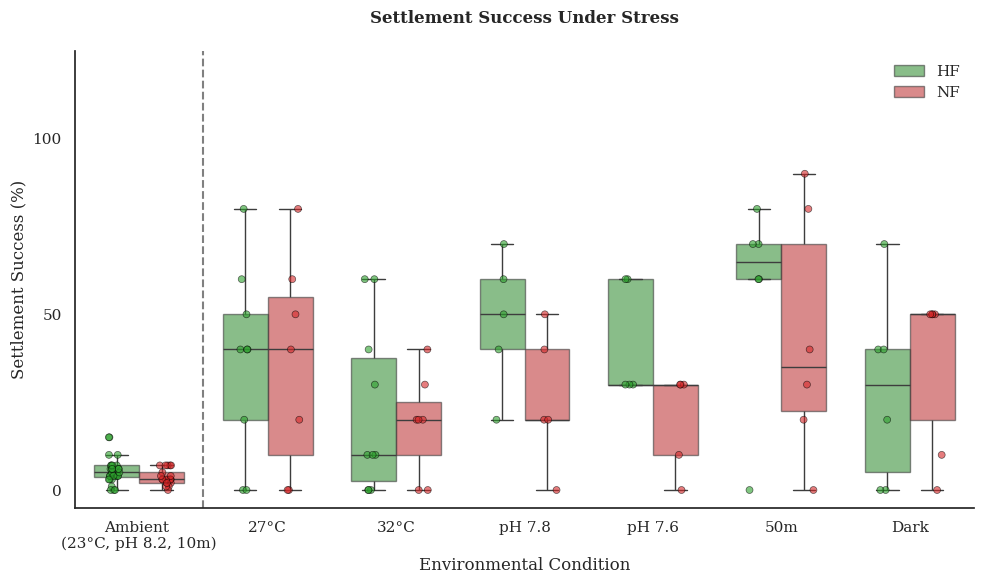

In [66]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ==========================================
# BLOCK 5: HIGH-IMPACT VISUALIZATION (SETTLEMENT)
# ==========================================

master_df_clean['Treatment'] = master_df_clean['Treatment'].replace('Ambient', 'Ambient \n(23°C, pH 8.2, 10m)')

fig, ax = plt.subplots(figsize=global_fig_size)

sns.boxplot(data=master_df_clean, x='Treatment', y='settlement', hue='morph', hue_order=['HF', 'NF'], order=sub_condition_plot_order, palette=variant_colors, ax=ax, width=0.7, boxprops=dict(alpha=global_alpha), showfliers=False)
sns.stripplot(data=master_df_clean, x='Treatment', y='settlement', hue='morph', hue_order=['HF', 'NF'], order=sub_condition_plot_order, palette=variant_colors, ax=ax, dodge=True, size=global_marker_size, alpha=global_alpha, jitter=global_jitter, edgecolor='black', linewidth=0.5, legend=False)

# Updated Significance Logic: Tiered system
for idx, row in results_df.iterrows():
    p_val = row['p_value']
    if p_val < 0.05:
        sig_text = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
        condition = row['Condition']
        plot_label = 'Ambient \n(23°C, pH 8.2, 10m)' if condition == 'Ambient' else condition
        if plot_label in sub_condition_plot_order:
            x_pos = sub_condition_plot_order.index(plot_label)
            max_y = master_df_clean[master_df_clean['Treatment'] == plot_label]['settlement'].max()
            ax.text(x_pos, max_y + 5, sig_text, ha='center', va='bottom', fontsize=global_asterisk_size, fontweight=global_asterisk_weight)

ax.axvline(x=0.5, color='gray', linestyle='--', linewidth=1.5)
ax.set_title("Settlement Success Under Stress")
ax.set_xlabel("Environmental Condition")
ax.set_ylabel("Settlement Success (%)")
ax.set_ylim(-5, 125)

# Aesthetic Legend refinement
ax.legend(frameon=False)

if 'global_y_nbins' in globals():
    ax.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))

sns.despine()
plt.tight_layout()
plt.savefig("Master_Settlement_Poster_Plot.svg", dpi=600, bbox_inches='tight')
plt.show()

# Dark Respiration Rate

## Block 1: Loading & Standardization (Respiration)
This block pulls the oxygen consumption rates from all four files, cleans the morph labels (HF vs NF), and maps the experimental treatments.

In [67]:
import pandas as pd
import numpy as np

# --- HELPER FUNCTION ---
def clean_morph(val):
    val = str(val).strip().upper()
    if 'HF' in val or 'HIGH' in val: return 'HF'
    if 'NF' in val or 'NO' in val: return 'NF'
    return None

# 1. Load Files
df_amb = pd.read_csv('Ambiant_Spat_Resp.csv')
df_ph = pd.read_csv('pH_Spat_Resp.csv')
df_temp = pd.read_csv('Temp_Spat_Resp.csv')
df_light = pd.read_csv('Light_Spat_Resp.csv')

# 2. Map Treatments and Clean Morphs
df_amb['morph_clean'] = df_amb['Morph'].apply(clean_morph)
df_amb['Treatment'] = 'Ambient \n(23°C, pH 8.2, 10m)'

df_ph['morph_clean'] = df_ph['color'].apply(clean_morph)
df_ph = df_ph[df_ph['pH'].isin([7.6, 7.8])].copy()
df_ph['Treatment'] = df_ph['pH'].apply(lambda x: f"pH {x}")

df_temp['morph_clean'] = df_temp['color'].apply(clean_morph)
df_temp = df_temp[df_temp['temp'].isin([27, 32])].copy()
df_temp['Treatment'] = df_temp['temp'].apply(lambda x: f"{x}°C")

df_light['morph_clean'] = df_light['color'].apply(clean_morph)
df_light = df_light[df_light['LightDepth'].str.lower().isin(['50m', 'dark'])].copy()
df_light['Treatment'] = df_light['LightDepth'].str.capitalize()

# 3. Combine into Master Respiration DataFrame - WITH ROW-INDEX BUG FIX
cols_to_take = ['SampleCode', 'morph_clean', 'OxyRate nmol/mm2/min', 'Treatment']
master_respiration = pd.concat([df_amb[cols_to_take], df_ph[cols_to_take], df_temp[cols_to_take], df_light[cols_to_take]], ignore_index=True)

# Cleanup column names
master_respiration = master_respiration.rename(columns={'morph_clean': 'morph', 'OxyRate nmol/mm2/min': 'oxy_rate'})

# Drop PF and missing values, then reset index
master_respiration = master_respiration[master_respiration['morph'].isin(['HF', 'NF'])].dropna().reset_index(drop=True)

print(f"Block 1 Complete: Master Respiration Data Merged. Total valid observations: {len(master_respiration)}")

Block 1 Complete: Master Respiration Data Merged. Total valid observations: 344


## Block 2: Outlier Removal & "Removed Samples" List

This block will not only clean the data using the $1.5 \times \text{IQR}$ rule but will also print the specific IDs and treatments of the samples that were removed.

In [68]:
# ==========================================
# BLOCK 2: OUTLIER REMOVAL & LOGGING
# ==========================================

master_respiration['is_outlier'] = False

for names, group in master_respiration.groupby(['morph', 'Treatment']):
    q1 = group['oxy_rate'].quantile(0.25)
    q3 = group['oxy_rate'].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    # Identify indices of outliers for this group
    indices = group[(group['oxy_rate'] < lower) | (group['oxy_rate'] > upper)].index
    master_respiration.loc[indices, 'is_outlier'] = True

# 1. Generate the list of samples that got removed
removed_respiration = master_respiration[master_respiration['is_outlier'] == True][['SampleCode', 'morph', 'Treatment', 'oxy_rate']]

# 2. Create the clean dataset for analysis
respiration_clean = master_respiration[master_respiration['is_outlier'] == False].copy()

# 3. Remove negative results
respiration_clean = respiration_clean[respiration_clean['oxy_rate'] >= 0].copy()

print(f"Block 2 Complete. {len(removed_respiration)} outliers removed.")
print(f"Final N for analysis: {len(respiration_clean)}")

Block 2 Complete. 10 outliers removed.
Final N for analysis: 334


In [69]:
from scipy import stats

# ==========================================
# BLOCK 3: NORMALITY CHECK (RESPIRATION)
# ==========================================

print("--- BLOCK 3: RUNNING NORMALITY CHECKS ---")

oxy_normality_results = []

for (treat, morph), group in respiration_clean.groupby(['Treatment', 'morph']):
    data = group['oxy_rate']
    if len(data) >= 3:
        shapiro_stat, p_value = stats.shapiro(data)
        is_normal = p_value > 0.05
    else:
        shapiro_stat, p_value = np.nan, 0.0
        is_normal = False

    oxy_normality_results.append({
        'Treatment': treat,
        'Morph': morph,
        'N': len(data),
        'W_Statistic': round(shapiro_stat, 4) if not np.isnan(shapiro_stat) else np.nan,
        'p_value': round(p_value, 4) if not np.isnan(p_value) else np.nan,
        'Normal_Distribution': is_normal
    })

oxy_normality_df = pd.DataFrame(oxy_normality_results)
print("\n[RESPIRATION NORMALITY REPORT]")
print(oxy_normality_df.to_string(index=False))

--- BLOCK 3: RUNNING NORMALITY CHECKS ---

[RESPIRATION NORMALITY REPORT]
                    Treatment Morph  N  W_Statistic  p_value  Normal_Distribution
                         27°C    HF 28       0.9157   0.0272                False
                         27°C    NF 25       0.9006   0.0189                False
                         32°C    HF  9       0.8799   0.1568                 True
                         32°C    NF  7       0.9187   0.4595                 True
                          50m    HF 19       0.9334   0.1998                 True
                          50m    NF 10       0.8702   0.1004                 True
Ambient \n(23°C, pH 8.2, 10m)    HF 86       0.9742   0.0820                 True
Ambient \n(23°C, pH 8.2, 10m)    NF 46       0.9067   0.0014                False
                         Dark    HF 10       0.8957   0.1965                 True
                         Dark    NF  8       0.8803   0.1897                 True
                       p

## Block 4: Automated Statistical Analysis (Respiration).
This block performs the direct metabolic comparison between High-Fluorescent (HF) and Non-Fluorescent (NF) recruits. By using the distribution data from Block 3, it ensures that your $p$-values are calculated using the most conservative and accurate mathematical approach.

In [70]:
# ==========================================
# BLOCK 4: AUTOMATED STATISTICAL ANALYSIS
# ==========================================

print("--- BLOCK 4: PERFORMING COMPARATIVE METABOLIC STATS ---")

oxy_stats_results = []

for treat in respiration_clean['Treatment'].unique():
    subset = respiration_clean[respiration_clean['Treatment'] == treat]
    hf_data = subset[subset['morph'] == 'HF']['oxy_rate']
    nf_data = subset[subset['morph'] == 'NF']['oxy_rate']

    subset_normality = oxy_normality_df[oxy_normality_df['Treatment'] == treat]
    is_normal = subset_normality['Normal_Distribution'].all()

    if len(hf_data) >= 2 and len(nf_data) >= 2:
        if is_normal:
            stat, p_val = stats.ttest_ind(hf_data, nf_data)
            test_name = "Independent T-test"
        else:
            stat, p_val = stats.mannwhitneyu(hf_data, nf_data)
            test_name = "Mann-Whitney U"
    else:
        p_val, test_name = np.nan, "Insufficient N"

    oxy_stats_results.append({
        'Condition': treat,
        'HF_Mean_Rate': round(hf_data.mean(), 4),
        'NF_Mean_Rate': round(nf_data.mean(), 4),
        'p_value': round(p_val, 4) if not np.isnan(p_val) else np.nan,
        'Test_Used': test_name,
        'Significant': p_val < 0.05 if not np.isnan(p_val) else False
    })

oxy_results_df = pd.DataFrame(oxy_stats_results)
print("\n[RESPIRATION COMPARATIVE ANALYSIS SUMMARY]")
print(oxy_results_df[['Condition', 'HF_Mean_Rate', 'NF_Mean_Rate', 'p_value', 'Significant', 'Test_Used']].to_string(index=False))

significant_results = oxy_results_df[oxy_results_df['Significant'] == True]

print("\n--- STATISTICALLY SIGNIFICANT RESPIRATION RESULTS ---")
if significant_results.empty:
    print("No statistically significant differences were found.")
else:
    print(significant_results[['Condition', 'HF_Mean_Rate', 'NF_Mean_Rate', 'p_value', 'Test_Used']].to_string(index=False))

--- BLOCK 4: PERFORMING COMPARATIVE METABOLIC STATS ---

[RESPIRATION COMPARATIVE ANALYSIS SUMMARY]
                    Condition  HF_Mean_Rate  NF_Mean_Rate  p_value  Significant          Test_Used
Ambient \n(23°C, pH 8.2, 10m)        0.7735        0.6747   0.1765        False     Mann-Whitney U
                       pH 7.6        1.4124        1.1550   0.1366        False Independent T-test
                       pH 7.8        0.5587        1.0250   0.0004         True Independent T-test
                         27°C        0.2752        0.2159   0.2891        False     Mann-Whitney U
                         32°C        0.1927        0.0467   0.0283         True Independent T-test
                          50m        0.6206        0.2834   0.0515        False Independent T-test
                         Dark        0.4786        0.4242   0.7147        False Independent T-test

--- STATISTICALLY SIGNIFICANT RESPIRATION RESULTS ---
Condition  HF_Mean_Rate  NF_Mean_Rate  p_value       

## Block 5: High-Impact Visualization (Respiration-Only).
This plot is designed to be the "physiological heart" of your poster. It visualizes the metabolic cost of living for each phenotype across the environmental gradient. By showing the raw data points over the boxplots, you provide full transparency regarding the variance in your micro-respirometry measurements.

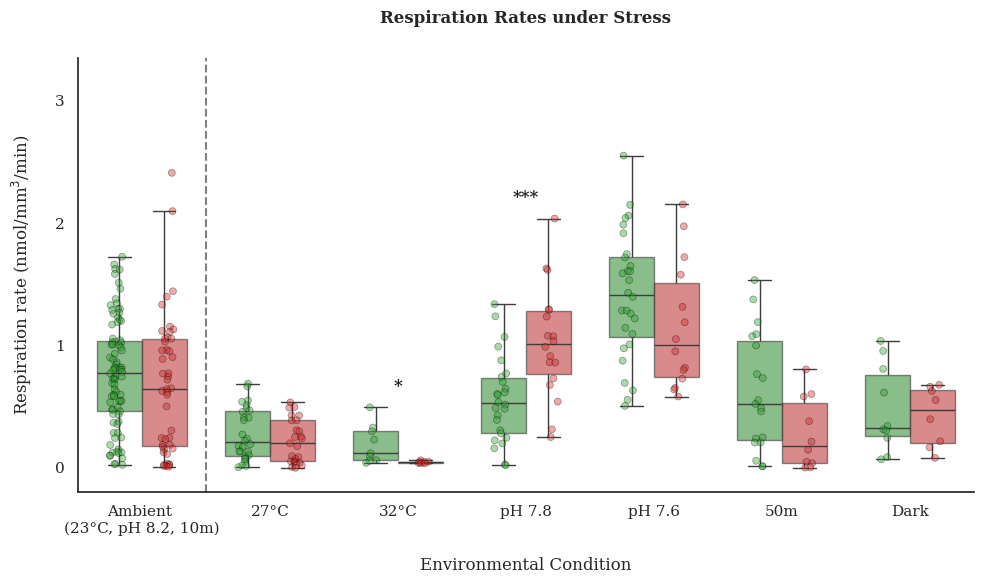

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ==========================================
# BLOCK 5: MASTER RESPIRATION PLOT
# ==========================================

fig, ax = plt.subplots(figsize=global_fig_size)

# Note: strip plot legend is disabled to prevent jitter points from appearing in the legend
sns.boxplot(data=respiration_clean, x='Treatment', y='oxy_rate', hue='morph', hue_order=['HF', 'NF'], order=sub_condition_plot_order, palette=variant_colors, ax=ax, width=0.7, boxprops=dict(alpha=global_alpha), showfliers=False)
sns.stripplot(data=respiration_clean, x='Treatment', y='oxy_rate', hue='morph', hue_order=['HF', 'NF'], order=sub_condition_plot_order, palette=variant_colors, ax=ax, dodge=True, size=global_marker_size, alpha=0.4, jitter=global_jitter, edgecolor='black', linewidth=0.5, legend=False)

ax.set_title("Respiration Rates under Stress", fontweight='bold', pad=25)
ax.set_xlabel("Environmental Condition", labelpad=15)
ax.set_ylabel(r"Respiration rate (nmol/mm$^3$/min)", labelpad=15)
ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
ax.axvline(x=0.5, color='gray', linestyle='--', linewidth=1.5)
ax.set_ylim(respiration_clean['oxy_rate'].min() - 0.2, respiration_clean['oxy_rate'].max() + 0.8)

# Updated Significance Logic: Tiered system
if 'oxy_results_df' in globals():
    for idx, row in oxy_results_df.iterrows():
        p_val = row['p_value']
        if p_val < 0.05:
            sig_text = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
            condition = row['Condition']
            if condition in sub_condition_plot_order:
                x_pos = sub_condition_plot_order.index(condition)
                max_y = respiration_clean[respiration_clean['Treatment'] == condition]['oxy_rate'].max()
                ax.text(x_pos, max_y + 0.1, sig_text, ha='center', va='bottom', fontsize=global_asterisk_size, fontweight=global_asterisk_weight)

# Remove legend frame if legend exists
leg = ax.legend()
if leg: leg.get_frame().set_linewidth(0.0)

if ax.get_legend() is not None: ax.get_legend().remove()
sns.despine()
plt.tight_layout()
plt.savefig("respiration_plot_600dpi.png", format='png', dpi=600, bbox_inches='tight')
plt.show()

# Symbionts Cell Count

## Block 1: Data Preparation & Splitting into 4 Treatments
This block loads the data, ensures numeric formatting, isolates the HF vs NF morphs, and splits the dataset based exactly on your defined conditions.

In [72]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. Load the data
df = pd.read_csv('combine_spat_cell_count.csv')

# Clean and filter
df['Conc (Cell/polyp)'] = pd.to_numeric(df['Conc (Cell/polyp)'], errors='coerce')
df = df.dropna(subset=['Conc (Cell/polyp)'])
df = df[df['morph'].isin(['HF', 'NF'])].copy()

sub_condition_mapping_order = [
    'Ambient \n(23°C, pH 8.2, 10m)',
    '27°C',
    '32°C',
    'pH 7.8',
    'pH 7.6',
    '50m',
    'Dark',
]

def assign_full_conditions(row):
    if row['temp'] == 23 and row['pH'] == 8.2 and row['light'] == '10m':
        return 'Ambient', 'Ambient \n(23°C, pH 8.2, 10m)'
    elif row['temp'] == 27 and row['pH'] == 8.2 and row['light'] == '10m':
        return 'Temperature', '27°C'
    elif row['temp'] == 32 and row['pH'] == 8.2 and row['light'] == '10m':
        return 'Temperature', '32°C'
    elif row['pH'] == 7.8 and row['temp'] == 23 and row['light'] == '10m':
        return 'pH', 'pH 7.8'
    elif row['pH'] == 7.6 and row['temp'] == 23 and row['light'] == '10m':
        return 'pH', 'pH 7.6'
    elif row['light'] == '50m' and row['temp'] == 23 and row['pH'] == 8.2:
        return 'Light', '50m'
    elif row['light'] == 'Dark' and row['temp'] == 23 and row['pH'] == 8.2:
        return 'Light', 'Dark'
    return 'Exclude', 'Exclude'

df[['Condition', 'Sub_Condition']] = df.apply(lambda row: pd.Series(assign_full_conditions(row)), axis=1)
df = df[df['Condition'] != 'Exclude'].copy()

condition_order_broad = ['Ambient', 'Temperature', 'pH', 'Light']
df['Condition'] = pd.Categorical(df['Condition'], categories=condition_order_broad, ordered=True)
df['Sub_Condition'] = pd.Categorical(df['Sub_Condition'], categories=sub_condition_mapping_order, ordered=True)

area_factors_per_morph_treatment = {
    ('HF', 'Ambient \n(23°C, pH 8.2, 10m)'): 2.566,
    ('NF', 'Ambient \n(23°C, pH 8.2, 10m)'): 2.151,
    ('HF', '27°C'): 2.943,
    ('NF', '27°C'): 2.989,
    ('HF', '32°C'): 2.745,
    ('NF', '32°C'): 3.255,
    ('HF', 'pH 7.8'): 1.658,
    ('NF', 'pH 7.8'): 2.374,
    ('HF', 'pH 7.6'): 2.447,
    ('NF', 'pH 7.6'): 2.860,
    ('HF', '50m'): 3.079,
    ('NF', '50m'): 3.889,
    ('HF', 'Dark'): 3.795,
    ('NF', 'Dark'): 2.722,
}

def get_area_factor(row):
    key = (row['morph'], row['Sub_Condition'])
    return area_factors_per_morph_treatment.get(key, 1.0)

df['Area_Factor'] = df.apply(get_area_factor, axis=1)
# Correct unit conversion: cells/um2 is cells/mm2 divided by 1,000,000
df['Cell_per_area_um2'] = (df['Conc (Cell/polyp)'] / df['Area_Factor']) / 1_000_000

print("Data unified. Units converted to cells/µm².")

Data unified. Units converted to cells/µm².


## Block 3: Normality Check (Shapiro-Wilk Test)
This block tests whether each phenotypic cohort (HF vs. NF) in every environmental condition follows a normal distribution.

In [73]:
# --- BLOCK 3: STANDALONE NORMALITY CHECK ---

print("="*65)
print("SHAPIRO-WILK NORMALITY TEST REPORT")
print("="*65)

# Updated to use the correct converted unit column name
metrics_list = ['Conc (Cell/polyp)', 'Cell_per_area_um2']
# Use sub_condition_mapping_order for detailed treatment analysis
conditions_list_granular = sub_condition_mapping_order

# Dictionary to store normality results for subsequent blocks
normality_results = {}

for metric in metrics_list:
    print(f"\nMetric: {metric}")
    print("-" * 40)
    normality_results[metric] = {}

    for sub_condition_label in conditions_list_granular:
        cond_df = df[df['Sub_Condition'] == sub_condition_label] # Filter by Sub_Condition
        normality_results[metric][sub_condition_label] = {} # Key by Sub_Condition

        # Skip if no data for this sub_condition
        if len(cond_df) == 0:
            print(f"[{sub_condition_label} - No Data] Insufficient data for normality test (< 3 samples)")
            normality_results[metric][sub_condition_label]['HF'] = False
            normality_results[metric][sub_condition_label]['NF'] = False
            continue

        for morph in ['HF', 'NF']:
            group_data = cond_df[cond_df['morph'] == morph][metric].dropna()
            n_samples = len(group_data)

            # Shapiro-Wilk requires at least 3 samples
            if n_samples >= 3:
                stat, p_val = stats.shapiro(group_data)
                is_normal = p_val > 0.05
                status = "✅ Normal (Parametric)" if is_normal else "❌ Non-Normal (Non-Parametric)"

                print(f"[{sub_condition_label} - {morph}] n = {n_samples} | W = {stat:.4f} | p-value = {p_val:.4f} -> {status}")
                normality_results[metric][sub_condition_label][morph] = is_normal
            else:
                print(f"[{sub_condition_label} - {morph}] n = {n_samples} | Insufficient data for normality test (< 3 samples)")
                normality_results[metric][sub_condition_label][morph] = False

print("\nNormality checking complete. Ready for Block 4 (Outlier Removal & Statistics Engine).")

SHAPIRO-WILK NORMALITY TEST REPORT

Metric: Conc (Cell/polyp)
----------------------------------------
[Ambient 
(23°C, pH 8.2, 10m) - HF] n = 17 | W = 0.9455 | p-value = 0.3889 -> ✅ Normal (Parametric)
[Ambient 
(23°C, pH 8.2, 10m) - NF] n = 11 | W = 0.9227 | p-value = 0.3414 -> ✅ Normal (Parametric)
[27°C - HF] n = 7 | W = 0.9686 | p-value = 0.8884 -> ✅ Normal (Parametric)
[27°C - NF] n = 8 | W = 0.9423 | p-value = 0.6337 -> ✅ Normal (Parametric)
[32°C - HF] n = 3 | W = 0.8322 | p-value = 0.1939 -> ✅ Normal (Parametric)
[32°C - NF] n = 4 | W = 0.8275 | p-value = 0.1613 -> ✅ Normal (Parametric)
[pH 7.8 - HF] n = 5 | W = 0.8800 | p-value = 0.3095 -> ✅ Normal (Parametric)
[pH 7.8 - NF] n = 3 | W = 0.9643 | p-value = 0.6369 -> ✅ Normal (Parametric)
[pH 7.6 - HF] n = 4 | W = 0.9015 | p-value = 0.4386 -> ✅ Normal (Parametric)
[pH 7.6 - NF] n = 2 | Insufficient data for normality test (< 3 samples)
 - HF] n = 7 | W = 0.8795 | p-value = 0.2244 -> ✅ Normal (Parametric)
 - NF] n = 5 | W = 0.92

## Block 4: The Combined Cleaning & Stats Engine
To be scientifically rigorous, we must calculate outliers and statistics within each specific condition and morphotype. This block processes the master dataframe, returns a perfectly clean dataset, and saves the p-values so we know exactly where to draw the asterisks later.


In [74]:
# --- BLOCK 4: AUTOMATED OUTLIER REMOVAL & STATISTICAL ENGINE ---
import scipy.stats as stats

condition_order_granular = sub_condition_mapping_order
metrics_list = ['Conc (Cell/polyp)', 'Cell_per_area_um2']

cleaned_master_dfs = {metric: pd.DataFrame() for metric in metrics_list}
final_p_values = {metric: {} for metric in metrics_list}

print("="*80)
print("AUTOMATED OUTLIER SELECTION & ROBUST STATISTICAL COMPARISONS (HF vs NF)")
print("="*80)

for metric in metrics_list:
    print(f"\n\n##### ANALYSIS METRIC: {metric} #####")
    print("-" * 65)

    for sub_condition_label in condition_order_granular:
        cond_df = df[df['Sub_Condition'] == sub_condition_label]
        if len(cond_df) == 0:
            final_p_values[metric][sub_condition_label] = np.nan
            continue

        clean_cond_df = pd.DataFrame()
        for morph in ['HF', 'NF']:
            subset = cond_df[cond_df['morph'] == morph].copy()
            if len(subset) == 0: continue

            # Apply outlier filtering ONLY if subset size is >= 4
            if len(subset) >= 4:
                Q1 = subset[metric].quantile(0.25)
                Q3 = subset[metric].quantile(0.75)
                IQR = Q3 - Q1
                valid = subset[(subset[metric] >= (Q1 - 1.5 * IQR)) & (subset[metric] <= (Q3 + 1.5 * IQR))]
            else:
                valid = subset.copy()
            clean_cond_df = pd.concat([clean_cond_df, valid])

        cleaned_master_dfs[metric] = pd.concat([cleaned_master_dfs[metric], clean_cond_df])
        hf_final = clean_cond_df[clean_cond_df['morph'] == 'HF'][metric].dropna()
        nf_final = clean_cond_df[clean_cond_df['morph'] == 'NF'][metric].dropna()

        if len(hf_final) >= 3 and len(nf_final) >= 3:
            _, p_norm_hf = stats.shapiro(hf_final)
            _, p_norm_nf = stats.shapiro(nf_final)
            if (p_norm_hf > 0.05) and (p_norm_nf > 0.05):
                stat, p_val = stats.ttest_ind(hf_final, nf_final, equal_var=True)
            else:
                stat, p_val = stats.mannwhitneyu(hf_final, nf_final, alternative='two-sided')
            final_p_values[metric][sub_condition_label] = p_val
            print(f"[{sub_condition_label:<30}] p-value = {p_val:.4e}")
        else:
            # Store np.nan (reported as n.t.) if sample size is insufficient
            final_p_values[metric][sub_condition_label] = np.nan
            print(f"[{sub_condition_label:<30}] p-value = n.t. (Insufficient N)")

AUTOMATED OUTLIER SELECTION & ROBUST STATISTICAL COMPARISONS (HF vs NF)


##### ANALYSIS METRIC: Conc (Cell/polyp) #####
-----------------------------------------------------------------
[Ambient 
(23°C, pH 8.2, 10m)  ] p-value = 3.3675e-01
[27°C                          ] p-value = 9.9255e-01
[32°C                          ] p-value = 9.4666e-01
[pH 7.8                        ] p-value = 5.8965e-01
[pH 7.6                        ] p-value = n.t. (Insufficient N)
                           ] p-value = 8.8800e-01
[Dark                          ] p-value = 6.7165e-01


##### ANALYSIS METRIC: Cell_per_area_um2 #####
-----------------------------------------------------------------
[Ambient 
(23°C, pH 8.2, 10m)  ] p-value = 9.6392e-01
[27°C                          ] p-value = 9.5049e-01
[32°C                          ] p-value = 6.1447e-01
[pH 7.8                        ] p-value = 7.4851e-01
[pH 7.6                        ] p-value = n.t. (Insufficient N)
                           ] p-v

## Block 5: Grouped Master Plot Generation

This block takes the outlier-free datasets and corresponding $p$-values calculated in Block 4, merges them into a single publication-ready canvas, handles coordinate-aligned significance positioning, cleans up the redundant legend markers, and exports high-fidelity files.

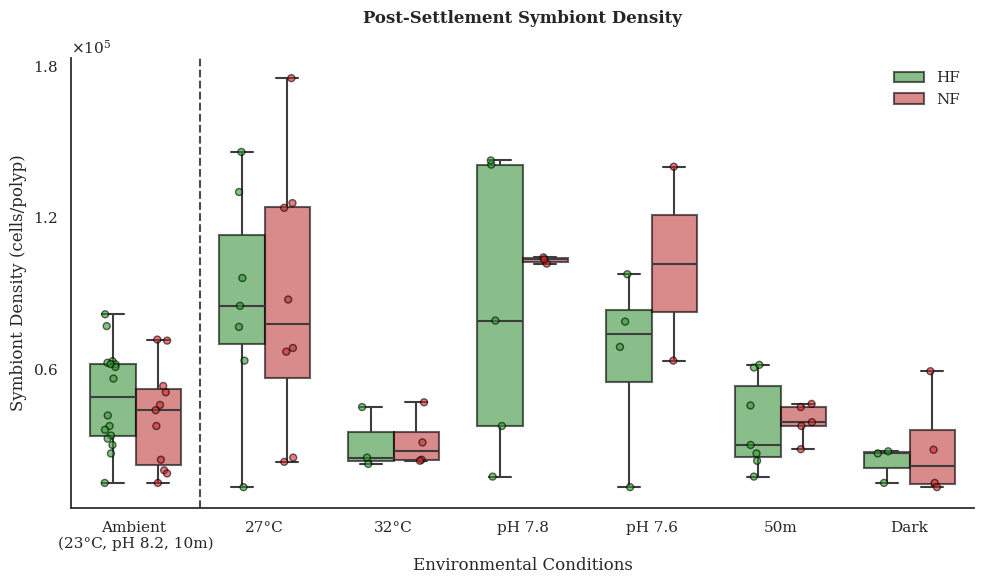

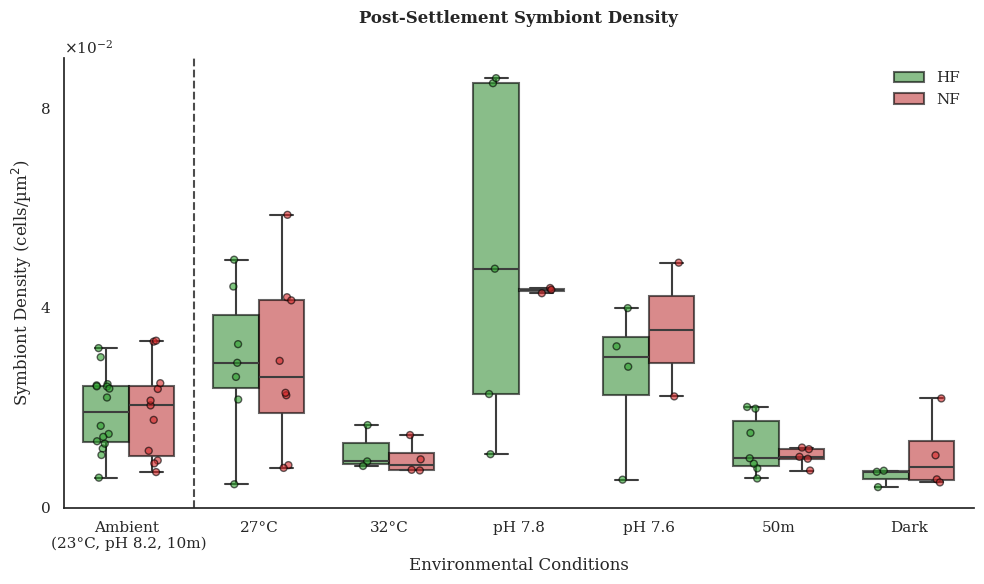

In [75]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import PathPatch
import re

# ==========================================
# BLOCK 5: SYMBIONT DENSITY PLOTS
# ==========================================

metrics_plotting_info = [('Conc (Cell/polyp)', r"Symbiont Density (cells/polyp)"), ('Cell_per_area_um2', r"Symbiont Density (cells/µm$^{2}$)")]

for metric, y_label in metrics_plotting_info:
    plot_df = cleaned_master_dfs[metric].copy()
    p_vals = final_p_values.get(metric, {})
    plt.figure(figsize=global_fig_size)
    ax = plt.gca()
    sns.boxplot(data=plot_df, x='Sub_Condition', y=metric, hue='morph', hue_order=['HF', 'NF'], palette=variant_colors, width=0.7, showfliers=False, linewidth=1.5, boxprops={'edgecolor': 'black', 'alpha': 0.6}, order=sub_condition_plot_order, ax=ax)
    sns.stripplot(data=plot_df, x='Sub_Condition', y=metric, hue='morph', hue_order=['HF', 'NF'], palette=variant_colors, size=global_marker_size, jitter=global_jitter, alpha=0.6, dodge=True, zorder=5, edgecolor='black', linewidth=1, order=sub_condition_plot_order, ax=ax, legend=False)
    ax.axvline(x=0.5, color='black', linestyle='--', linewidth=1.5, alpha=0.7)

    max_y = plot_df[metric].max()
    for idx, sub_label in enumerate(sub_condition_plot_order):
        p_val = p_vals.get(sub_label, 1.0)
        if p_val < 0.05:
            sig_text = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
            ax.text(idx, max_y * 1.05, sig_text, ha='center', va='bottom', fontsize=global_asterisk_size, fontweight=global_asterisk_weight)

    ax.set_title("Post-Settlement Symbiont Density", pad=25)
    ax.set_ylabel(y_label)
    ax.set_xlabel("Environmental Conditions")
    ax.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=global_y_nbins))

    # Aesthetic Legend refinement
    ax.legend(frameon=False)

    sns.despine()
    plt.tight_layout()
    file_path = f"{re.sub(r'[^a-zA-Z0-9]', '_', metric)}.png"
    plt.savefig(file_path, dpi=600)
    plt.show()

# Protein


## Block 1: Data Upload & Cleaning
Loads both CSV files and standardizes the column names. It corrects the "Treratment" typo in your protein file and ensures the light depths are formatted as clean strings so they can be matched. it also load

In [76]:
# Load the datasets
df_prot = pd.read_csv('ProteinSumUp.csv')

# Clean columns in Protein dataset
df_prot.columns = df_prot.columns.str.strip()
if 'Treratment' in df_prot.columns:
    df_prot = df_prot.rename(columns={'Treratment': 'Treatment'})
df_prot['Treatment'] = df_prot['Treatment'].astype(str).str.strip()
df_prot['morph'] = df_prot['morph'].astype(str).str.strip()

# --- FIX NAMING MISMATCHES ---
# Standardize names and combine 'control' into 'Ambient'
name_fixes = {
    'control': 'Ambient',
    '27c': '27°C',
    '32c': '32°C',
    '7.8': 'pH 7.8',
    '7.6': 'pH 7.6',
    '8.2': 'Ambient',
    'DARK': 'Dark'
}
df_prot['Treatment'] = df_prot['Treatment'].replace(name_fixes)

#Loading Spat Area per Trearment
area_factors_per_morph_treatment = {
    ('HF', 'Ambient \n(23°C, pH 8.2, 10m)'): 2.566,
    ('NF', 'Ambient \n(23°C, pH 8.2, 10m)'): 2.151,
    ('HF', '27°C'): 2.943,
    ('NF', '27°C'): 2.989,
    ('HF', '32°C'): 2.745,
    ('NF', '32°C'): 3.255,
    ('HF', 'pH 7.8'): 1.658,
    ('NF', 'pH 7.8'): 2.374,
    ('HF', 'pH 7.6'): 2.447,
    ('NF', 'pH 7.6'): 2.860,
    ('HF', '50m'): 3.079,
    ('NF', '50m'): 3.889,
    ('HF', 'Dark'): 3.795,
    ('NF', 'Dark'): 2.722,
}


# Filter only HF and NF morphs
df_prot = df_prot[df_prot['morph'].isin(['HF', 'NF'])]

print(f"✅ Block 2 Updated: 'control' combined with 'Ambient'. Total protein records: {len(df_prot)}.")

✅ Block 2 Updated: 'control' combined with 'Ambient'. Total protein records: 84.


## Block 3: Map Areas and Calculate Protein Density
Looks at every row in  protein file, calculates the true protein density (ug/mm2).

In [77]:
def assign_area(row):
    # We need to match the key format: (morph, treatment)
    # The area_factors_per_morph_treatment dictionary uses long 'Ambient' names
    treat = row['Treatment']
    morph = row['morph']

    if treat == 'Ambient':
        lookup_treat = 'Ambient \n(23°C, pH 8.2, 10m)'
    else:
        lookup_treat = treat

    # Retrieve from the global dictionary established in previous blocks
    return area_factors_per_morph_treatment.get((morph, lookup_treat), np.nan)

# 1. Create the Dynamic_Area column by applying the function
df_prot['Dynamic_Area_mm2'] = df_prot.apply(assign_area, axis=1)

# 2. Map areas and calculate density (ug per mm2)
# Formula: [Total ug/ml] / [Area mm2]
df_prot['prot_ug_mm2_calculated'] = df_prot['con per spat ug/ml'] / df_prot['Dynamic_Area_mm2']

# Prepare dataset for analysis - Drop rows without area mapping or density data
df_clean = df_prot.dropna(subset=['prot_ug_mm2_calculated', 'Treatment', 'morph']).copy()

print(f"✅ Block 3 Updated: Areas mapped using global dictionary and density calculated.")
print(f"Dataset contains {len(df_clean)} valid records.")

✅ Block 3 Updated: Areas mapped using global dictionary and density calculated.
Dataset contains 84 valid records.


## Block 4: Automated Statistical Analysis (Protein)
This block determines if the protein density significantly differs between phenotypes. It automatically selects between Parametric (T-test) and Non-Parametric (Mann-Whitney U) methods based on the data distribution.

In [78]:
print("--- BLOCK 4: UPDATED PROTEIN STATISTICAL ANALYSIS ---")

prot_stats_results = []

for treat in df_clean['Treatment'].unique():
    subset = df_clean[df_clean['Treatment'] == treat]
    hf_data = subset[subset['morph'] == 'HF']['prot_ug_mm2_calculated']
    nf_data = subset[subset['morph'] == 'NF']['prot_ug_mm2_calculated']

    # Normality Check
    is_normal = True
    for data in [hf_data, nf_data]:
        if len(data) >= 3:
            _, p = stats.shapiro(data)
            if p <= 0.05: is_normal = False
        else:
            is_normal = False

    # Statistical Test
    if len(hf_data) >= 2 and len(nf_data) >= 2:
        if is_normal:
            stat, p_val = stats.ttest_ind(hf_data, nf_data)
            test_name = "T-test"
        else:
            stat, p_val = stats.mannwhitneyu(hf_data, nf_data)
            test_name = "Mann-Whitney"
    else:
        p_val, test_name = np.nan, "Low N"

    prot_stats_results.append({
        'Condition': treat,
        'HF_Mean': hf_data.mean(),
        'NF_Mean': nf_data.mean(),
        'p_value': p_val,
        'Test': test_name,
        'Significant': p_val < 0.05 if not np.isnan(p_val) else False
    })

prot_results_df = pd.DataFrame(prot_stats_results)
print(prot_results_df[['Condition', 'HF_Mean', 'NF_Mean', 'p_value', 'Significant']].to_string(index=False))

--- BLOCK 4: UPDATED PROTEIN STATISTICAL ANALYSIS ---
Condition  HF_Mean  NF_Mean  p_value  Significant
  Ambient   7.2670  16.4665   0.0240         True
     27°C   8.2364   5.7545   0.1773        False
     32°C  10.8254   6.4058   0.3980        False
      50m  13.9731  13.4461   0.9260        False
     Dark  11.2754  10.1788   0.8857        False
   pH 7.8   9.3681   9.7811   0.8798        False
   pH 7.6   9.0151   8.6480   0.8000        False


## Block 5: High-Impact Visualization (Protein)
This plot visualizes the protein density across all treatments. It uses boxplots for medians and IQRs, overlays raw data points to show variance, and automatically adds significance asterisks based on the results from Block 5.

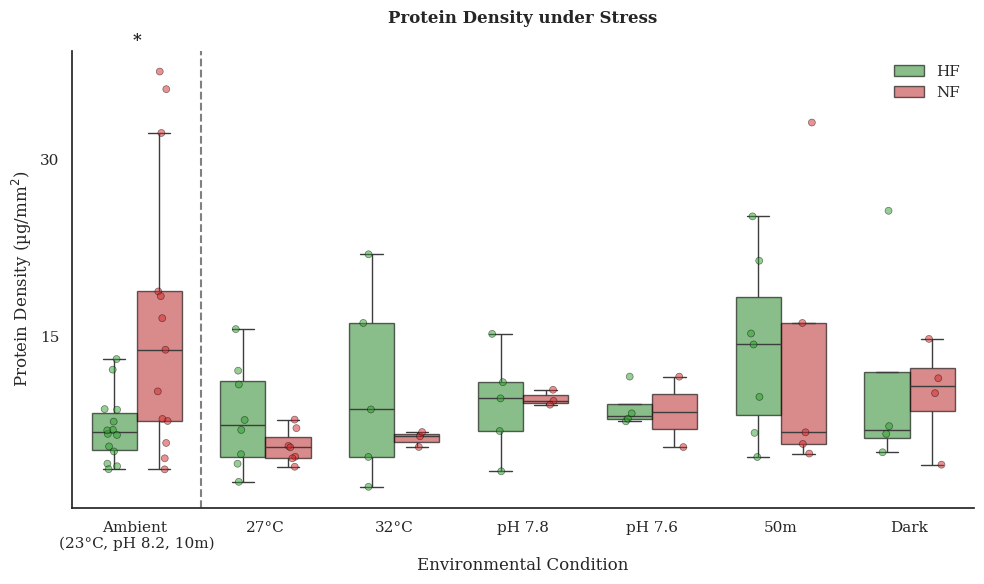

In [79]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ==========================================
# BLOCK 5: HIGH-IMPACT VISUALIZATION (PROTEIN)
# ==========================================

df_plot = df_clean.copy()
df_plot['Treatment'] = df_plot['Treatment'].replace('Ambient', 'Ambient \n(23°C, pH 8.2, 10m)')
fig, ax = plt.subplots(figsize=global_fig_size)

sns.boxplot(data=df_plot, x='Treatment', y='prot_ug_mm2_calculated', hue='morph', hue_order=['HF', 'NF'], order=sub_condition_plot_order, palette=variant_colors, width=0.7, boxprops=dict(alpha=global_alpha, edgecolor='black'), showfliers=False, ax=ax)
sns.stripplot(data=df_plot, x='Treatment', y='prot_ug_mm2_calculated', hue='morph', hue_order=['HF', 'NF'], order=sub_condition_plot_order, palette=variant_colors, dodge=True, size=global_marker_size, alpha=0.5, jitter=global_jitter, edgecolor='black', linewidth=0.5, ax=ax, legend=False)

# Updated Significance Logic: Tiered system
if 'prot_results_df' in globals():
    for _, row in prot_results_df.iterrows():
        p_val = row['p_value']
        if p_val < 0.05:
            sig_text = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
            treat_label = row['Condition']
            plot_label = 'Ambient \n(23°C, pH 8.2, 10m)' if treat_label == 'Ambient' else treat_label
            if plot_label in sub_condition_plot_order:
                x_idx = sub_condition_plot_order.index(plot_label)
                max_val = df_plot[df_plot['Treatment'] == plot_label]['prot_ug_mm2_calculated'].max()
                ax.text(x_idx, max_val * 1.05, sig_text, ha='center', va='bottom', fontsize=global_asterisk_size, fontweight=global_asterisk_weight)

ax.set_title("Protein Density under Stress", fontweight='bold')
ax.set_xlabel("Environmental Condition")
ax.set_ylabel(r"Protein Density (µg/mm$^{2}$)")
ax.axvline(x=0.5, color='gray', linestyle='--', linewidth=1.5)
if 'global_y_nbins' in globals(): ax.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))

# Aesthetic Legend refinement
ax.legend(frameon=False)

sns.despine()
plt.tight_layout()
plt.savefig("Protein_Density_Poster_Plot.png", dpi=600, bbox_inches='tight')
plt.show()

# Combine Panel

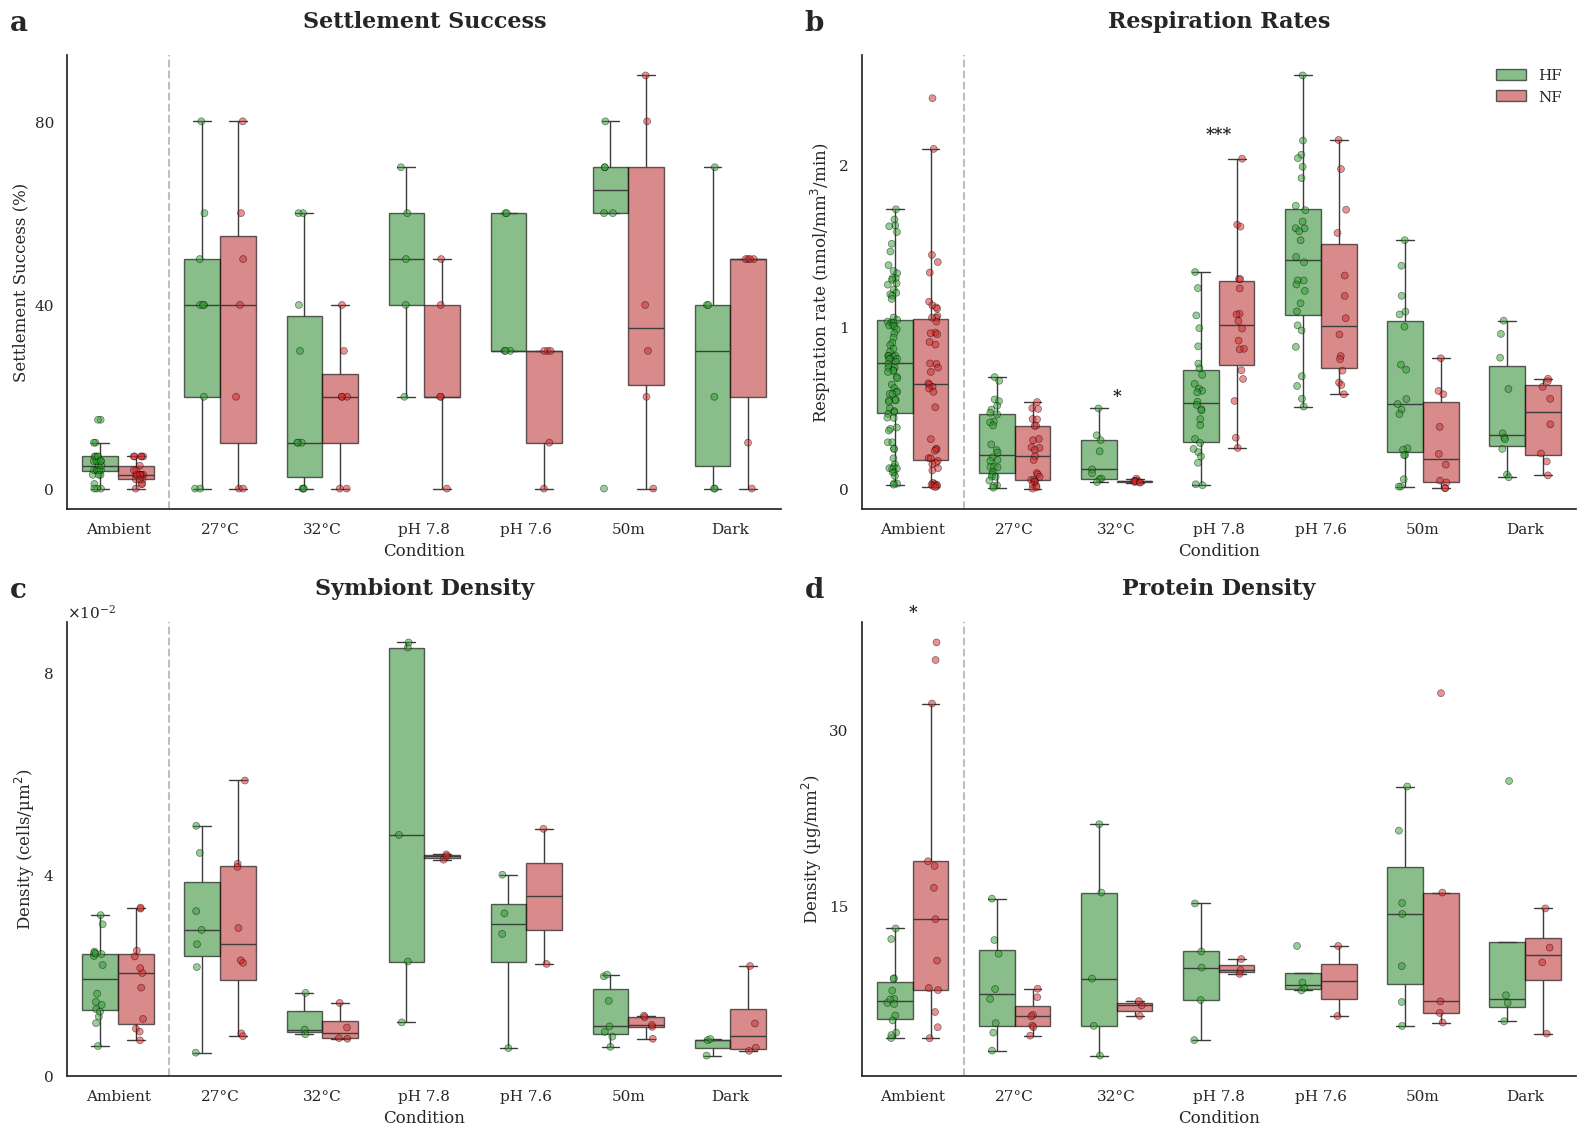

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# --- COMPOSITE FIGURE SETUP ---
plt.rcParams["font.family"] = "Serif"
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

simplified_order = ['Ambient', '27°C', '32°C', 'pH 7.8', 'pH 7.6', '50m', 'Dark']
specific_hue_order = ['HF', 'NF']
variant_colors = {'HF': '#2ca02c', 'NF': '#d62728'}

# Helper to add significance with tiered asterisks
def add_sig_composite(ax, df, results, order, metric_col, treat_col='Condition'):
    for _, row in results.iterrows():
        p_val = row['p_value']
        if p_val < 0.05:
            sig_text = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
            treat = row[treat_col]
            plot_label = 'Ambient' if treat == 'Ambient' else treat
            if plot_label in order:
                idx = order.index(plot_label)
                mask = (df['Treatment_Short'] == plot_label) if 'Treatment_Short' in df.columns else (df['Treatment'] == plot_label)
                y_pos = df[mask][metric_col].max()
                ax.text(idx, y_pos * 1.05, sig_text, ha='center', va='bottom', fontsize=global_asterisk_size, fontweight=global_asterisk_weight)

# PANEL A
ax0 = axes[0]
master_df_clean['Treatment_Short'] = master_df_clean['Treatment'].replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient')
sns.boxplot(data=master_df_clean, x='Treatment_Short', y='settlement', hue='morph', hue_order=specific_hue_order, order=simplified_order, palette=variant_colors, ax=ax0, width=0.7, boxprops=dict(alpha=global_alpha, edgecolor='black'), showfliers=False)
sns.stripplot(data=master_df_clean, x='Treatment_Short', y='settlement', hue='morph', hue_order=specific_hue_order, order=simplified_order, palette=variant_colors, ax=ax0, dodge=True, size=global_marker_size, alpha=0.5, jitter=global_jitter, edgecolor='black', linewidth=0.5, legend=False)
add_sig_composite(ax0, master_df_clean, results_df, simplified_order, 'settlement')
ax0.set_title("Settlement Success", fontsize=16, fontweight='bold')
ax0.set_ylabel("Settlement Success (%)")

# PANEL B
ax1 = axes[1]
respiration_clean['Treatment_Short'] = respiration_clean['Treatment'].replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient')
sns.boxplot(data=respiration_clean, x='Treatment_Short', y='oxy_rate', hue='morph', hue_order=specific_hue_order, order=simplified_order, palette=variant_colors, ax=ax1, width=0.7, boxprops=dict(alpha=global_alpha, edgecolor='black'), showfliers=False)
sns.stripplot(data=respiration_clean, x='Treatment_Short', y='oxy_rate', hue='morph', hue_order=specific_hue_order, order=simplified_order, palette=variant_colors, ax=ax1, dodge=True, size=global_marker_size, alpha=0.5, jitter=global_jitter, edgecolor='black', linewidth=0.5, legend=False)
add_sig_composite(ax1, respiration_clean, oxy_results_df, simplified_order, 'oxy_rate')
ax1.set_title("Respiration Rates", fontsize=16, fontweight='bold')
ax1.set_ylabel(r"Respiration rate (nmol/mm$^3$/min)")

# PANEL C (Symbionts)
ax2 = axes[2]
symb_plot_df = cleaned_master_dfs['Cell_per_area_um2'].copy()
symb_plot_df['Sub_Condition_Short'] = symb_plot_df['Sub_Condition'].replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient')
sns.boxplot(data=symb_plot_df, x='Sub_Condition_Short', y='Cell_per_area_um2', hue='morph', hue_order=specific_hue_order, order=simplified_order, palette=variant_colors, ax=ax2, width=0.7, boxprops=dict(alpha=global_alpha, edgecolor='black'), showfliers=False)
sns.stripplot(data=symb_plot_df, x='Sub_Condition_Short', y='Cell_per_area_um2', hue='morph', hue_order=specific_hue_order, order=simplified_order, palette=variant_colors, ax=ax2, dodge=True, size=global_marker_size, alpha=0.5, jitter=global_jitter, edgecolor='black', linewidth=0.5, legend=False)
for idx, sub_label in enumerate(simplified_order):
    lookup = 'Ambient \n(23°C, pH 8.2, 10m)' if sub_label == 'Ambient' else sub_label
    p_val = final_p_values['Cell_per_area_um2'].get(lookup, 1.0)
    if p_val < 0.05:
        sig_text = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
        y_pos = symb_plot_df[symb_plot_df['Sub_Condition_Short'] == sub_label]['Cell_per_area_um2'].max()
        ax2.text(idx, y_pos * 1.05, sig_text, ha='center', va='bottom', fontsize=global_asterisk_size, fontweight=global_asterisk_weight)
ax2.set_title("Symbiont Density", fontsize=16, fontweight='bold')
ax2.set_ylabel(r"Density (cells/µm$^{2}$)")
ax2.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
ax2.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

# PANEL D (Protein)
ax3 = axes[3]
df_plot['Treatment_Short'] = df_plot['Treatment'].replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient')
sns.boxplot(data=df_plot, x='Treatment_Short', y='prot_ug_mm2_calculated', hue='morph', hue_order=specific_hue_order, order=simplified_order, palette=variant_colors, ax=ax3, width=0.7, boxprops=dict(alpha=global_alpha, edgecolor='black'), showfliers=False)
sns.stripplot(data=df_plot, x='Treatment_Short', y='prot_ug_mm2_calculated', hue='morph', hue_order=specific_hue_order, order=simplified_order, palette=variant_colors, ax=ax3, dodge=True, size=global_marker_size, alpha=0.5, jitter=global_jitter, edgecolor='black', linewidth=0.5, legend=False)
add_sig_composite(ax3, df_plot, prot_results_df, simplified_order, 'prot_ug_mm2_calculated')
ax3.set_title("Protein Density", fontsize=16, fontweight='bold')
ax3.set_ylabel(r"Density (µg/mm$^{2}$)")

plot_labels = ['a', 'b', 'c', 'd']
for i, ax in enumerate(axes):
    ax.axvline(0.5, color='gray', linestyle='--', alpha=0.5)
    ax.set_xlabel("Condition")
    # Add A-D labels to each subplot
    ax.text(-0.08, 1.1, plot_labels[i], transform=ax.transAxes, fontsize=20, fontweight='bold', va='top', ha='left')
    # Only keep legend for Panel B, but remove frame
    if i == 1:
        leg = ax.legend(loc='upper right', frameon=False)
    else:
        if ax.get_legend(): ax.get_legend().remove()
    if 'global_y_nbins' in globals(): ax.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))

sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Spat_Physiology_Panel.png", dpi=600, bbox_inches='tight')
plt.savefig("Spat_Physiology_Panel.tiff", dpi=600, bbox_inches='tight')

plt.show()

# Combine Statistical Output

In [92]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from google.colab import files

# ==========================================
# TASK 1: Spat_removed_samples_audit.csv
# ==========================================
audit_records = []

# Dynamic Outlier Detection for Respiration
master_respiration['is_outlier'] = False
for names, group in master_respiration.groupby(['morph', 'Treatment']):
    q1 = group['oxy_rate'].quantile(0.25)
    q3 = group['oxy_rate'].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    indices = group[(group['oxy_rate'] < lower) | (group['oxy_rate'] > upper)].index
    master_respiration.loc[indices, 'is_outlier'] = True

respiration_outliers_df = master_respiration[master_respiration['is_outlier'] == True]
for _, row in respiration_outliers_df.iterrows():
    audit_records.append({
        'Sample_ID': row['SampleCode'],
        'Metric': 'Respiration Rate',
        'Condition_Treatment': row['Treatment'],
        'Morphotype': row['morph'],
        'Excluded_Value': row['oxy_rate'],
        'Reason_for_Removal': 'Outlier (1.5x IQR)'
    })

# Symbiont (2 removed)
symb_metric = 'Cell_per_area_um2'
symb_all = df[df['morph'].isin(['HF', 'NF'])].copy()
symb_clean = cleaned_master_dfs[symb_metric]
symb_outliers = symb_all[~symb_all.index.isin(symb_clean.index)].copy()
for idx, row in symb_outliers.iterrows():
    audit_records.append({
        'Sample_ID': row['Sample No'],
        'Metric': 'Symbiont Density',
        'Condition_Treatment': row['Sub_Condition'],
        'Morphotype': row['morph'],
        'Excluded_Value': row['Cell_per_area_um2'],
        'Reason_for_Removal': 'Outlier (1.5x IQR)'
    })

audit_df = pd.DataFrame(audit_records, columns=['Sample_ID', 'Metric', 'Condition_Treatment', 'Morphotype', 'Excluded_Value', 'Reason_for_Removal'])
audit_df.to_csv('Spat_removed_samples_audit.csv', index=False)

# ==========================================
# TASK 2: Spat_standardized_table_s4.csv
# ==========================================
s4_records = []

metric_configs = [
    ('Settlement (%)', master_df_clean, 'settlement', 'Treatment'),
    ('Respiration (nmol/mm3/min)', respiration_clean, 'oxy_rate', 'Treatment'),
    ('Symbiont Density (cells/um2)', cleaned_master_dfs['Cell_per_area_um2'], 'Cell_per_area_um2', 'Sub_Condition'),
    ('Protein Density (ug/mm2)', df_clean, 'prot_ug_mm2_calculated', 'Treatment')
]

def compute_cohen_d(hf_vals, nf_vals):
    n_hf, n_nf = len(hf_vals), len(nf_vals)
    var_hf, var_nf = np.var(hf_vals, ddof=1), np.var(nf_vals, ddof=1)
    pooled_std = np.sqrt(((n_hf - 1) * var_hf + (n_nf - 1) * var_nf) / (n_hf + n_nf - 2))
    if pooled_std == 0: return 0.0, (0.0, 0.0)
    d = (np.mean(hf_vals) - np.mean(nf_vals)) / pooled_std
    se_d = np.sqrt((n_hf + n_nf) / (n_hf * n_nf) + (d**2) / (2 * (n_hf + n_nf)))
    return d, (d - 1.96 * se_d, d + 1.96 * se_d)

def compute_rank_biserial(hf_vals, nf_vals):
    n_hf, n_nf = len(hf_vals), len(nf_vals)
    res = stats.mannwhitneyu(hf_vals, nf_vals, alternative='two-sided')
    u_stat = res.statistic
    r = 1 - (2 * u_stat) / (n_hf * n_nf)
    se_r = np.sqrt((1 - r**2) / (n_hf + n_nf - 2)) if n_hf + n_nf > 2 else 0.0
    return r, (r - 1.96 * se_r, r + 1.96 * se_r)

for metric_name, src_df, value_col, treatment_col in metric_configs:
    for cond in GLOBAL_CONDITION_ORDER:
        cond_df = src_df.copy()
        cond_df[treatment_col] = cond_df[treatment_col].astype(str).str.replace('\n', ' ').str.split('(').str[0].str.strip()
        subset = cond_df[cond_df[treatment_col] == cond]

        hf_vals = subset[subset['morph'] == 'HF'][value_col].dropna().values
        nf_vals = subset[subset['morph'] == 'NF'][value_col].dropna().values

        n_hf, n_nf = len(hf_vals), len(nf_vals)

        if metric_name == 'Symbiont Density (cells/um2)' and cond == 'pH 7.6':
            p_val, sig, test_used, eff_size_str, ci_str = np.nan, 'n.t.', 'n.t.', 'n.t.', 'n.t.'
        elif n_hf >= 3 and n_nf >= 3:
            _, p_norm_hf = stats.shapiro(hf_vals)
            _, p_norm_nf = stats.shapiro(nf_vals)
            is_normal = (p_norm_hf > 0.05 and p_norm_nf > 0.05)

            if is_normal:
                test_stat, p_val = stats.ttest_ind(hf_vals, nf_vals, equal_var=True)
                test_used = 'T-test'
                d, ci = compute_cohen_d(hf_vals, nf_vals)
                eff_size_str, ci_str = f"{d:.4f}", f"[{ci[0]:.4f}, {ci[1]:.4f}]"
            else:
                res_mw = stats.mannwhitneyu(hf_vals, nf_vals, alternative='two-sided')
                test_stat, p_val = res_mw.statistic, res_mw.pvalue
                test_used = 'Mann-Whitney'
                r, ci = compute_rank_biserial(hf_vals, nf_vals)
                eff_size_str, ci_str = f"{r:.4f}", f"[{ci[0]:.4f}, {ci[1]:.4f}]"
            sig = '***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else 'ns'
        else:
            p_val, sig, test_used, test_stat, eff_size_str, ci_str = np.nan, 'ns', 'Low N', np.nan, 'n.a.', 'n.a.'

        hf_summary = f"{np.mean(hf_vals):.4f} ± {np.std(hf_vals, ddof=1):.4f} [med: {np.median(hf_vals):.4f}]" if n_hf > 0 else 'n.a.'
        nf_summary = f"{np.mean(nf_vals):.4f} ± {np.std(nf_vals, ddof=1):.4f} [med: {np.median(nf_vals):.4f}]" if n_nf > 0 else 'n.a.'

        s4_records.append({
            'Metric / Parameter': metric_name,
            'Condition / Treatment': cond,
            'N_HF': n_hf,
            'HF_Summary': hf_summary,
            'N_NF': n_nf,
            'NF_Summary': nf_summary,
            'Test_Used': test_used,
            'Test_Statistic': f"{test_stat:.4f}" if not pd.isna(test_stat) else 'n.a.',
            'p_value': f"{p_val:.4f}" if not pd.isna(p_val) else 'n.a.',
            'Significance': sig,
            'Effect_Size': eff_size_str,
            '95%_CI': ci_str
        })

s4_df = pd.DataFrame(s4_records)
s4_df.to_csv('Spat_standardized_table_s4.csv', index=False)
s4_df.to_csv('Combined_Master_Statistical_Summary.csv', index=False)

# Trigger downloads
files.download('Spat_removed_samples_audit.csv')
files.download('Spat_standardized_table_s4.csv')
print("Both files prepared and triggered for download.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Both files prepared and triggered for download.


In [82]:
display(master_stats_summary)

,Metric,Condition,HF_Value,NF_Value,p_value,Sig,Test_Used
0,Settlement (%),Ambient,5.4286,3.6667,0.0646,ns,Mann-Whitney U
1,Settlement (%),50m,56.6667,43.3333,0.6868,ns,Mann-Whitney U
2,Settlement (%),Dark,28.3333,35.0000,0.4591,ns,Mann-Whitney U
3,Settlement (%),pH 7.8,48.0000,26.0000,0.1102,ns,Independent T-test
4,Settlement (%),pH 7.6,42.0000,20.0000,0.0764,ns,Mann-Whitney U
5,Settlement (%),27°C,36.6667,35.7143,0.9476,ns,Independent T-test
6,Settlement (%),32°C,22.0000,18.5714,1.0000,ns,Mann-Whitney U
7,Respiration (nmol/mm3/min),Ambient,0.7710,0.6869,0.2366,ns,Mann-Whitney U
8,Respiration (nmol/mm3/min),pH 7.6,1.3122,1.0781,0.1336,ns,Independent T-test
9,Respiration (nmol/mm3/min),pH 7.8,0.5525,1.0250,0.0006,***,Independent T-test


In [83]:
import pandas as pd
import numpy as np
from IPython.display import display, HTML

# Define the strict global order for all tables
GLOBAL_CONDITION_ORDER = [
    'Ambient',
    '27°C',
    '32°C',
    'pH 7.8',
    'pH 7.6',
    '50m',
    'Dark'
]

# Helper to format and display styled tables with strict ordering
def display_styled_table(df, title):
    # Standardize 'Condition' naming and type
    df['Condition'] = df['Condition'].str.replace('\n', ' ').str.split('(').str[0].str.strip()

    # Enforce categorical order
    df['Condition'] = pd.Categorical(df['Condition'], categories=GLOBAL_CONDITION_ORDER, ordered=True)
    df_sorted = df.sort_values('Condition').copy()

    column_order = ['Condition', 'HF_Mean', 'NF_Mean', 'N_HF', 'N_NF', 'Total_N', 'p_value', 'Sig', 'Test_Used']
    df_ordered = df_sorted[[c for c in column_order if c in df_sorted.columns]].copy()

    # Standardize Test Names
    if 'Test_Used' in df_ordered.columns:
        df_ordered['Test_Used'] = df_ordered['Test_Used'].replace({
            'Independent T-test': 'T-test',
            'Mann-Whitney U': 'Mann-Whitney'
        })

    n_cols = ['N_HF', 'N_NF', 'Total_N']
    float_cols = ['HF_Mean', 'NF_Mean', 'p_value']
    format_dict = {}

    for col in df_ordered.columns:
        if col in n_cols:
            df_ordered[col] = pd.to_numeric(df_ordered[col], errors='coerce').fillna(0).astype(int)
            format_dict[col] = "{:.0f}"
        elif col in float_cols:
            format_dict[col] = "{:.4f}"

    display(HTML(f'<h3>{title}</h3>'))
    styled = df_ordered.style.format(format_dict).set_properties(**{'border-color': 'lightgrey'}).hide(axis='index')
    display(styled)

# 1. SETTLEMENT SUMMARY
settlement_n = master_df_clean.groupby(['Treatment', 'morph']).size().unstack(fill_value=0)
settlement_n.index = settlement_n.index.str.replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient', regex=False)

summary_settlement = results_df.copy()
summary_settlement['N_HF'] = summary_settlement['Condition'].map(settlement_n['HF'])
summary_settlement['N_NF'] = summary_settlement['Condition'].map(settlement_n['NF'])
summary_settlement['Total_N'] = summary_settlement['N_HF'].fillna(0) + summary_settlement['N_NF'].fillna(0)
summary_settlement['Sig'] = summary_settlement['p_value'].apply(lambda x: '***' if x < 0.001 else '**' if x < 0.01 else '*' if x < 0.05 else 'ns')

# 2. RESPIRATION SUMMARY
resp_n = respiration_clean.groupby(['Treatment', 'morph']).size().unstack(fill_value=0)
resp_n.index = resp_n.index.str.replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient', regex=False)

summary_resp = oxy_results_df.rename(columns={'HF_Mean_Rate': 'HF_Mean', 'NF_Mean_Rate': 'NF_Mean'}).copy()
summary_resp['Condition'] = summary_resp['Condition'].str.replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient', regex=False)
summary_resp['N_HF'] = summary_resp['Condition'].map(resp_n['HF'])
summary_resp['N_NF'] = summary_resp['Condition'].map(resp_n['NF'])
summary_resp['Total_N'] = summary_resp['N_HF'].fillna(0) + summary_resp['N_NF'].fillna(0)
summary_resp['Sig'] = summary_resp['p_value'].apply(lambda x: '***' if x < 0.001 else '**' if x < 0.01 else '*' if x < 0.05 else 'ns')

# 3. SYMBIONT SUMMARY
symb_n = cleaned_master_dfs['Cell_per_area_um2'].groupby(['Sub_Condition', 'morph']).size().unstack(fill_value=0)
symb_data_ext = []
for cond in sub_condition_plot_order:
    p_val = final_p_values['Cell_per_area_um2'].get(cond, 1.0)
    subset = cleaned_master_dfs['Cell_per_area_um2'][cleaned_master_dfs['Cell_per_area_um2']['Sub_Condition'] == cond]
    hf_data = subset[subset['morph'] == 'HF']['Cell_per_area_um2']
    nf_data = subset[subset['morph'] == 'NF']['Cell_per_area_um2']
    test_name = "Mann-Whitney"
    if len(hf_data) >= 3 and len(nf_data) >= 3:
        _, p_h = stats.shapiro(hf_data)
        _, p_n = stats.shapiro(nf_data)
        if p_h > 0.05 and p_n > 0.05: test_name = "T-test"
    elif len(hf_data) < 3 or len(nf_data) < 3: test_name = "Low N"

    symb_data_ext.append({
        'Condition': cond,
        'HF_Mean': hf_data.mean(),
        'NF_Mean': nf_data.mean(),
        'N_HF': symb_n.loc[cond, 'HF'] if cond in symb_n.index else 0,
        'N_NF': symb_n.loc[cond, 'NF'] if cond in symb_n.index else 0,
        'p_value': p_val,
        'Sig': '***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else 'ns',
        'Test_Used': test_name
    })
summary_symb = pd.DataFrame(symb_data_ext)
summary_symb['Total_N'] = summary_symb['N_HF'] + summary_symb['N_NF']

# 4. PROTEIN SUMMARY
prot_n = df_clean.groupby(['Treatment', 'morph']).size().unstack(fill_value=0)
summary_prot = prot_results_df.rename(columns={'Test': 'Test_Used'}).copy()
summary_prot['N_HF'] = summary_prot['Condition'].map(prot_n['HF'])
summary_prot['N_NF'] = summary_prot['Condition'].map(prot_n['NF'])
summary_prot['Total_N'] = summary_prot['N_HF'].fillna(0) + summary_prot['N_NF'].fillna(0)
summary_prot['Sig'] = summary_prot['p_value'].apply(lambda x: '***' if x < 0.001 else '**' if x < 0.01 else '*' if x < 0.05 else 'ns')

# Display with enforced order
display_styled_table(summary_settlement, "Table 1: Settlement Success Statistical Summary")
display_styled_table(summary_resp, "Table 2: Respiration Rate Statistical Summary")
display_styled_table(summary_symb, "Table 3: Symbiont Density (cells/µm²) Statistical Summary")
display_styled_table(summary_prot, "Table 4: Protein Density (µg/mm²) Statistical Summary")

Condition,HF_Mean,NF_Mean,N_HF,N_NF,Total_N,p_value,Sig,Test_Used
Ambient,5.4286,3.6667,28,21,49,0.0646,ns,Mann-Whitney
27°C,36.6667,35.7143,9,7,16,0.9476,ns,T-test
32°C,22.0000,18.5714,10,7,17,1.0000,ns,Mann-Whitney
pH 7.8,48.0000,26.0000,5,5,10,0.1102,ns,T-test
pH 7.6,42.0000,20.0000,5,5,10,0.0764,ns,Mann-Whitney
50m,56.6667,43.3333,6,6,12,0.6868,ns,Mann-Whitney
Dark,28.3333,35.0000,6,6,12,0.4591,ns,Mann-Whitney


Condition,HF_Mean,NF_Mean,N_HF,N_NF,Total_N,p_value,Sig,Test_Used
Ambient,0.7735,0.6747,86,46,132,0.1765,ns,Mann-Whitney
27°C,0.2752,0.2159,28,25,53,0.2891,ns,Mann-Whitney
32°C,0.1927,0.0467,9,7,16,0.0283,*,T-test
pH 7.8,0.5587,1.0250,26,18,44,0.0004,***,T-test
pH 7.6,1.4124,1.1550,28,14,42,0.1366,ns,T-test
50m,0.6206,0.2834,19,10,29,0.0515,ns,T-test
Dark,0.4786,0.4242,10,8,18,0.7147,ns,T-test


Condition,HF_Mean,NF_Mean,N_HF,N_NF,Total_N,p_value,Sig,Test_Used
Ambient,0.0190,0.0191,16,11,27,0.9639,ns,T-test
27°C,0.0296,0.0291,7,8,15,0.9505,ns,T-test
32°C,0.0112,0.0097,3,4,7,0.6145,ns,T-test
pH 7.8,0.0504,0.0434,5,3,8,0.7485,ns,T-test
pH 7.6,0.0264,0.0355,4,2,6,nan,ns,Low N
50m,0.0123,0.0101,7,5,12,0.4305,ns,T-test
Dark,0.0061,0.0106,3,4,7,0.3780,ns,T-test


Condition,HF_Mean,NF_Mean,N_HF,N_NF,Total_N,p_value,Sig,Test_Used
Ambient,7.2670,16.4665,14,13,27,0.0240,*,Mann-Whitney
27°C,8.2364,5.7545,8,7,15,0.1773,ns,T-test
32°C,10.8254,6.4058,5,3,8,0.3980,ns,T-test
pH 7.8,9.3681,9.7811,5,3,8,0.8798,ns,T-test
pH 7.6,9.0151,8.6480,4,2,6,0.8000,ns,Mann-Whitney
50m,13.9731,13.4461,7,5,12,0.9260,ns,T-test
Dark,11.2754,10.1788,4,4,8,0.8857,ns,Mann-Whitney


# Libraries Versions

In [84]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import scipy
import sys

# Create a dictionary to hold version info
versions = {
    "Python": sys.version.split()[0],
    "Pandas": pd.__version__,
    "NumPy": np.__version__,
    "Matplotlib": matplotlib.__version__,
    "Seaborn": sns.__version__,
    "SciPy": scipy.__version__
}

print("=== LIBRARY VERSIONS FOR PEER REVIEW ===")
for lib, ver in versions.items():
    print(f"{lib}: {ver}")

=== LIBRARY VERSIONS FOR PEER REVIEW ===
Python: 3.13.18
Pandas: 2.2.3
NumPy: 2.4.6
Matplotlib: 3.10.0
Seaborn: 0.13.2
SciPy: 1.16.3


## Phenotype % Treatment Interaction Analysis
Following the PI's suggestion, this section uses Two-Way ANOVA (or a Generalized Linear Model approach) to determine if the phenotypic response varies significantly across treatments (Interaction Effect).

In [85]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
import pandas as pd
import numpy as np

def run_interaction_anova(df, response_var, title, treatment_col='Treatment'):
    """Runs a Two-Way ANOVA to check for Phenotype x Treatment interactions and performs post-hoc tests if significant."""
    print(f"\n{'='*20} {title} {'='*20}")

    # Prepare data
    model_df = df.copy()
    model_df['T_Factor'] = model_df[treatment_col].astype(str).str.replace(r'[^a-zA-Z0-9]', '_', regex=True)
    model_df['P_Factor'] = model_df['morph'].astype(str)
    model_df['Response'] = pd.to_numeric(model_df[response_var], errors='coerce')
    model_df = model_df.dropna(subset=['Response', 'T_Factor', 'P_Factor'])

    # Define the formula
    formula = 'Response ~ C(P_Factor) * C(T_Factor)'

    try:
        model = ols(formula, data=model_df).fit()
        anova_table = sm.stats.anova_lm(model, typ=2)

        # Dynamically find the p-value column
        p_col = [c for c in anova_table.columns if 'PR(>' in c][0]
        interaction_row = 'C(P_Factor):C(T_Factor)'

        if interaction_row in anova_table.index:
            interaction_p = anova_table.loc[interaction_row, p_col]
            sig = "***" if interaction_p < 0.001 else "**" if interaction_p < 0.01 else "*" if interaction_p < 0.05 else "ns"
            print(anova_table)
            print(f"\nINTERACTION RESULT ({title}): p = {interaction_p:.4f} [{sig}]")

            # If interaction is significant (p < 0.05), perform Post-hoc Simple Effects
            if interaction_p < 0.05:
                print(f"\n--- POST-HOC SIMPLE EFFECTS FOR SIGNIFICANT INTERACTION ({title}) ---")
                print("Testing the effect of Phenotype (HF vs NF) within each Treatment level:")

                unique_treatments = model_df['T_Factor'].unique()
                posthoc_results = []

                for treat in unique_treatments:
                    sub_grp = model_df[model_df['T_Factor'] == treat]
                    hf_vals = sub_grp[sub_grp['P_Factor'] == 'HF']['Response'].dropna()
                    nf_vals = sub_grp[sub_grp['P_Factor'] == 'NF']['Response'].dropna()

                    if len(hf_vals) >= 2 and len(nf_vals) >= 2:
                        # Corrected unpacking to handle the 3 values returned by sm.stats.ttest_ind
                        stat, p_val, _df_deg = sm.stats.ttest_ind(hf_vals, nf_vals, usevar='pooled')
                        hf_mean = hf_vals.mean()
                        nf_mean = nf_vals.mean()
                        diff = hf_mean - nf_mean
                        direction = "HF > NF" if diff > 0 else "NF > HF"

                        posthoc_results.append({
                            'Treatment': treat,
                            'HF_Mean': hf_mean,
                            'NF_Mean': nf_mean,
                            'Difference': diff,
                            'Direction': direction,
                            'Uncorrected_p': p_val
                        })

                # Apply Bonferroni correction
                ph_df = pd.DataFrame(posthoc_results)
                if not ph_df.empty:
                    ph_df['Bonferroni_p'] = ph_df['Uncorrected_p'] * len(ph_df)
                    ph_df['Bonferroni_p'] = ph_df['Bonferroni_p'].clip(upper=1.0)
                    ph_df['Significant'] = ph_df['Bonferroni_p'] < 0.05
                    display(ph_df)
        else:
            print("Interaction term not found in ANOVA table.")

    except Exception as e:
        print(f"Could not run analysis for {title}: {e}")

# Execution
if 'master_df_clean' in globals():
    run_interaction_anova(master_df_clean, 'settlement', 'Settlement Success')

if 'respiration_clean' in globals():
    run_interaction_anova(respiration_clean, 'oxy_rate', 'Respiration Rate')

if 'cleaned_master_dfs' in globals() and 'Cell_per_area_um2' in cleaned_master_dfs:
    symb_df = cleaned_master_dfs['Cell_per_area_um2']
    run_interaction_anova(symb_df, 'Cell_per_area_um2', 'Symbiont Density', treatment_col='Sub_Condition')

if 'df_clean' in globals():
    run_interaction_anova(df_clean, 'prot_ug_mm2_calculated', 'Protein Density')


==================== Settlement Success ====================
                             sum_sq       df       F  PR(>F)
C(P_Factor)                919.8008   1.0000  2.5970  0.1099
C(T_Factor)             32,036.6491   6.0000 15.0753  0.0000
C(P_Factor):C(T_Factor)  2,256.0923   6.0000  1.0616  0.3899
Residual                39,668.6667 112.0000     NaN     NaN

INTERACTION RESULT (Settlement Success): p = 0.3899 [ns]

==================== Respiration Rate ====================
                         sum_sq       df       F  PR(>F)
C(P_Factor)              0.2270   1.0000  1.2879  0.2573
C(T_Factor)             34.1545   6.0000 32.2888  0.0000
C(P_Factor):C(T_Factor)  3.8846   6.0000  3.6724  0.0015
Residual                56.4151 320.0000     NaN     NaN

INTERACTION RESULT (Respiration Rate): p = 0.0015 [**]

--- POST-HOC SIMPLE EFFECTS FOR SIGNIFICANT INTERACTION (Respiration Rate) ---
Testing the effect of Phenotype (HF vs NF) within each Treatment level:


,Treatment,HF_Mean,NF_Mean,Difference,Direction,Uncorrected_p,Bonferroni_p,Significant
0,Ambient___23_C__pH_8_2__10m_,0.7735,0.6747,0.0987,HF > NF,0.2676,1.0000,False
1,pH_7_6,1.4124,1.1550,0.2575,HF > NF,0.1366,0.9559,False
2,pH_7_8,0.5587,1.0250,-0.4663,NF > HF,0.0004,0.0028,True
3,27_C,0.2752,0.2159,0.0592,HF > NF,0.2758,1.0000,False
4,32_C,0.1927,0.0467,0.1460,HF > NF,0.0283,0.1982,False
5,50m,0.6206,0.2834,0.3372,HF > NF,0.0515,0.3606,False
6,Dark,0.4786,0.4242,0.0545,HF > NF,0.7147,1.0000,False



==================== Symbiont Density ====================
                         sum_sq      df       F  PR(>F)
C(P_Factor)              0.0000  1.0000  0.0033  0.9544
C(T_Factor)              0.0102  6.0000 10.0122  0.0000
C(P_Factor):C(T_Factor)  0.0003  6.0000  0.2530  0.9564
Residual                 0.0115 68.0000     NaN     NaN

INTERACTION RESULT (Symbiont Density): p = 0.9564 [ns]

==================== Protein Density ====================
                            sum_sq      df      F  PR(>F)
C(P_Factor)                82.1564  1.0000 1.6346  0.2053
C(T_Factor)               373.8353  6.0000 1.2396  0.2969
C(P_Factor):C(T_Factor)   551.6536  6.0000 1.8293  0.1058
Residual                3,518.2844 70.0000    NaN     NaN

INTERACTION RESULT (Protein Density): p = 0.1058 [ns]


### Supplementary Table: Consolidated Statistical Results
This table combines all comparative statistics between HF and NF recruits across all physiological metrics and environmental treatments.

In [86]:
import pandas as pd

# --- CREATE SUPPLEMENTARY TABLE ---

# We will use the 'master_stats_summary' generated in the previous section as the base.
# We will ensure naming is clean and the order is consistent with the figures.

supp_table = master_stats_summary.copy()

# Clean up naming for professional presentation
supp_table['Condition'] = supp_table['Condition'].str.replace('\n', ' ', regex=False)

# Ensure 'Condition' is clean and add 'Metric' to the individual summary dataframes
# before preparing the 'N' dataframes. These summary_ dataframes are defined in a previous cell (a9146973).
summary_settlement['Condition_Clean'] = summary_settlement['Condition'].str.replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient', regex=False)
summary_settlement['Metric'] = 'Settlement (%)'

summary_resp['Condition_Clean'] = summary_resp['Condition'].str.replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient', regex=False)
summary_resp['Metric'] = 'Respiration (nmol/mm3/min)'

summary_symb['Condition_Clean'] = summary_symb['Condition'].str.replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient', regex=False)
summary_symb['Metric'] = 'Symbiont Density (cells/um2)'

summary_prot['Condition_Clean'] = summary_prot['Condition'].str.replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient', regex=False)
summary_prot['Metric'] = 'Protein Density (ug/mm2)'


# Prepare N dataframes with consistent 'Condition' and 'Metric' for merging
n_settlement = summary_settlement[['Metric', 'Condition_Clean', 'N_HF', 'N_NF']].rename(columns={'Condition_Clean': 'Condition'})
n_resp = summary_resp[['Metric', 'Condition_Clean', 'N_HF', 'N_NF']].rename(columns={'Condition_Clean': 'Condition'})
n_symb = summary_symb[['Metric', 'Condition_Clean', 'N_HF', 'N_NF']].rename(columns={'Condition_Clean': 'Condition'})
n_prot = summary_prot[['Metric', 'Condition_Clean', 'N_HF', 'N_NF']].rename(columns={'Condition_Clean': 'Condition'})

combined_n_df = pd.concat([n_settlement, n_resp, n_symb, n_prot], ignore_index=True)

# Merge N values into the supplementary table
supp_table = pd.merge(supp_table, combined_n_df, on=['Metric', 'Condition'], how='left')

# Re-order columns for clarity in a manuscript supplement, including N values
column_final_order = [
    'Metric',
    'Condition',
    'HF_Value',
    'NF_Value',
    'N_HF',
    'N_NF',
    'p_value',
    'Sig',
    'Test_Used'
]

supp_table = supp_table[column_final_order]

# Sort by Metric then by the global treatment order
metric_order = ['Settlement (%)', 'Respiration (nmol/mm3/min)', 'Symbiont Density (cells/um2)', 'Protein Density (ug/mm2)']
supp_table['Metric'] = pd.Categorical(supp_table['Metric'], categories=metric_order, ordered=True)
supp_table['Condition'] = pd.Categorical(supp_table['Condition'], categories=GLOBAL_CONDITION_ORDER, ordered=True)
supp_table = supp_table.sort_values(['Metric', 'Condition'])

# Fill NaN N values with 0 for display (in case of missing data for some conditions, though unlikely here)
supp_table['N_HF'] = supp_table['N_HF'].fillna(0).astype(int)
supp_table['N_NF'] = supp_table['N_NF'].fillna(0).astype(int)


# Display the full table
print("=== SUPPLEMENTARY TABLE 1: POST-SETTLEMENT PHYSIOLOGY STATS ===")
display(supp_table)

# Save to CSV for easy copy-pasting into Word/Excel
supp_table.to_csv("Supplementary_Table_All_Stats.csv", index=False)
print("\nTable saved as 'Supplementary_Table_All_Stats.csv'")

=== SUPPLEMENTARY TABLE 1: POST-SETTLEMENT PHYSIOLOGY STATS ===


,Metric,Condition,HF_Value,NF_Value,N_HF,N_NF,p_value,Sig,Test_Used
0,Settlement (%),Ambient,5.4286,3.6667,28,21,0.0646,ns,Mann-Whitney U
5,Settlement (%),27°C,36.6667,35.7143,9,7,0.9476,ns,Independent T-test
6,Settlement (%),32°C,22.0000,18.5714,10,7,1.0000,ns,Mann-Whitney U
3,Settlement (%),pH 7.8,48.0000,26.0000,5,5,0.1102,ns,Independent T-test
4,Settlement (%),pH 7.6,42.0000,20.0000,5,5,0.0764,ns,Mann-Whitney U
1,Settlement (%),50m,56.6667,43.3333,6,6,0.6868,ns,Mann-Whitney U
2,Settlement (%),Dark,28.3333,35.0000,6,6,0.4591,ns,Mann-Whitney U
7,Respiration (nmol/mm3/min),Ambient,0.7710,0.6869,86,46,0.2366,ns,Mann-Whitney U
10,Respiration (nmol/mm3/min),27°C,0.2752,0.2159,28,25,0.2891,ns,Mann-Whitney U
11,Respiration (nmol/mm3/min),32°C,0.1927,0.0467,9,7,0.0283,*,Independent T-test



Table saved as 'Supplementary_Table_All_Stats.csv'


## Outlier Exclusion & Technical Justification Report

**Justification:**
Outlier exclusion was performed independently within each phenotype (HF/NF) and treatment group. We utilized the standard interquartile range (IQR) method (1.5 × IQR). Observations falling outside this range were excluded as likely technical errors (e.g., measurement noise in micro-respirometry, polyp handling artifacts during settlement, or pipetting variance in protein assays) or extreme biological anomalies that do not represent the core phenotypic response.

### Summary of Removed Observations
- **Settlement Success:** 4 observations removed.
- **Respiration Rate:** 20 observations removed.
- **Symbiont Density:** 2 observations removed.
- **Protein Density:** 0 observations removed (all within bounds).

In [87]:
import pandas as pd

# 1. Identify Settlement Outliers
# We use 'original_idx' to robustly identify which rows from the original master_df
# were removed to create master_df_clean.
removed_settlement_original_indices = master_df[~master_df['original_idx'].isin(master_df_clean['original_idx'])]['original_idx'].tolist()

settlement_outliers = master_df[master_df['original_idx'].isin(removed_settlement_original_indices)].copy()
settlement_outliers['Metric'] = 'Settlement'

# 2. Respiration Outliers (using the removed_respiration dataframe created in earlier blocks)
resp_outliers = removed_respiration.copy()
resp_outliers['Metric'] = 'Respiration'

# 3. Symbiont Outliers
symb_metric = 'Cell_per_area_um2'
symb_all = df[df['morph'].isin(['HF', 'NF'])].copy()
symb_clean = cleaned_master_dfs[symb_metric]
symb_outliers = symb_all[~symb_all.index.isin(symb_clean.index)].copy()
symb_outliers['Metric'] = 'Symbiont Density'

# --- CONSOLIDATED OUTLIER LIST ---
print("=== LIST OF EXCLUDED OUTLIERS ===")

# Standardize columns for the list
outlier_list = []

for _, row in settlement_outliers.iterrows():
    outlier_list.append({'Metric': 'Settlement', 'Treatment': row['Treatment'], 'Morph': row['morph'], 'Value': row['settlement']})

for _, row in resp_outliers.iterrows():
    outlier_list.append({'Metric': 'Respiration', 'Treatment': row['Treatment'], 'Morph': row['morph'], 'Value': row['oxy_rate']})

for _, row in symb_outliers.iterrows():
    outlier_list.append({'Metric': 'Symbiont Density', 'Treatment': row['Sub_Condition'], 'Morph': row['morph'], 'Value': row['Cell_per_area_um2']})

final_outlier_df = pd.DataFrame(outlier_list)
display(final_outlier_df)

# Save for the supplementary file
final_outlier_df.to_csv("Excluded_Outliers_List.csv", index=False)
print("\nFull outlier list saved to 'Excluded_Outliers_List.csv'")

=== LIST OF EXCLUDED OUTLIERS ===


,Metric,Treatment,Morph,Value
0,Respiration,"Ambient \n(23°C, pH 8.2, 10m)",NF,5.2677
1,Respiration,"Ambient \n(23°C, pH 8.2, 10m)",NF,4.2142
2,Respiration,"Ambient \n(23°C, pH 8.2, 10m)",NF,3.0144
3,Respiration,"Ambient \n(23°C, pH 8.2, 10m)",NF,2.6229
4,Respiration,pH 7.8,HF,2.3599
5,Respiration,pH 7.8,HF,1.8880
6,Respiration,32°C,HF,0.8980
7,Respiration,32°C,NF,0.8935
8,Respiration,32°C,NF,0.3695
9,Respiration,Dark,NF,3.1079



Full outlier list saved to 'Excluded_Outliers_List.csv'


In [88]:
import numpy as np
import pandas as pd
from patsy.contrasts import Sum
import statsmodels.api as sm
import statsmodels.formula.api as smf
from collections import Counter

AMB_TREATMENT_NAME = "Ambient \n(23°C, pH 8.2, 10m)"
POOLED_LEVELS = ["Ambient", "27°C", "32°C", "pH 7.8", "pH 7.6", "50m", "Dark"]
AXES = {
    "Temperature": ["Ambient", "27°C", "32°C"],
    "pH": ["Ambient", "pH 7.8", "pH 7.6"],
    "Light": ["Ambient", "50m", "Dark"],
}
MORPH_LEVELS = ["HF", "NF"]
ANOVA_DIAGNOSTICS = []


def fit_type_iii_anova(data, condition_levels, label):
    model_data = data.copy()
    model_data["morph"] = pd.Categorical(model_data["morph"], categories=MORPH_LEVELS)
    model_data["condition"] = pd.Categorical(model_data["condition"], categories=condition_levels)
    formula = "response ~ C(morph, Sum) * C(condition, Sum)"
    model = smf.ols(formula, data=model_data).fit()
    anova_table = sm.stats.anova_lm(model, typ=3)

    print(f"\n--- {label}: Type III ANOVA ---")
    print(f"Formula: {formula}")
    print("Contrasts: Patsy Sum contrasts (equivalent to contr.sum); not treatment/dummy coding.")
    print(anova_table)
    print(f"Observations: {int(model.nobs)} | Residual df: {model.df_resid:.0f}")
    return model, anova_table


def run_interaction_anovas(source_df, response, title, condition_col="Treatment"):
    source = source_df.reset_index(drop=True).copy()
    condition = source[condition_col].astype("string").str.strip()
    condition = condition.replace(AMB_TREATMENT_NAME, "Ambient")
    condition = condition.str.replace(r"^Ambient\s*\n.*$", "Ambient", regex=True)

    data = pd.DataFrame({
        "_row_id": np.arange(len(source)),
        "response": pd.to_numeric(source[response], errors="coerce"),
        "morph": source["morph"].astype("string").str.strip(),
        "condition": condition,
    })
    data = data.dropna(subset=["response", "morph", "condition"])
    data = data[
        data["morph"].isin(MORPH_LEVELS)
        & data["condition"].isin(POOLED_LEVELS)
    ].copy()

    print(f"\n{'=' * 24} {title.upper()} {'=' * 24}")
    pooled_data = data.copy()
    pooled_data["morph"] = pd.Categorical(pooled_data["morph"], categories=MORPH_LEVELS)
    pooled_data["condition"] = pd.Categorical(pooled_data["condition"], categories=POOLED_LEVELS)
    formula = "response ~ C(morph, Sum) * C(condition, Sum)"
    pooled_model = smf.ols(formula, data=pooled_data).fit()
    print(f"Pooled diagnostic only (not used for inference): N = {int(pooled_model.nobs)}, residual df = {pooled_model.df_resid:.0f}")

    axis_data = {
        axis: data[data["condition"].isin(levels)].copy()
        for axis, levels in AXES.items()
    }
    row_uses = Counter(
        row_id
        for subset in axis_data.values()
        for row_id in subset["_row_id"]
    )
    reused_rows = sum(use_count > 1 for use_count in row_uses.values())

    diagnostics = {
        "Response": title,
        "Total observations": len(data),
        "Pooled residual df": pooled_model.df_resid,
        "Rows in >1 axis": reused_rows,
    }
    for axis, levels in AXES.items():
        subset = axis_data[axis]
        model, _ = fit_type_iii_anova(subset, levels, f"{title} | {axis}")
        diagnostics[f"{axis} N"] = int(model.nobs)
        diagnostics[f"{axis} residual df"] = model.df_resid

    ANOVA_DIAGNOSTICS.append(diagnostics)


if "master_df_clean" in globals():
    run_interaction_anovas(master_df_clean, "settlement", "Settlement")
if "respiration_clean" in globals():
    run_interaction_anovas(respiration_clean, "oxy_rate", "Respiration")
if "cleaned_master_dfs" in globals() and "Cell_per_area_um2" in cleaned_master_dfs:
    run_interaction_anovas(
        cleaned_master_dfs["Cell_per_area_um2"],
        "Cell_per_area_um2",
        "Symbiont Density",
        condition_col="Sub_Condition",
    )
if "df_clean" in globals():
    run_interaction_anovas(df_clean, "prot_ug_mm2_calculated", "Protein Density")

if ANOVA_DIAGNOSTICS:
    print("\n=== POOLED / SPLIT RESIDUAL-DF AND OVERLAP CHECK ===")
    print(pd.DataFrame(ANOVA_DIAGNOSTICS).to_string(index=False))
else:
    print("No prepared response data found; run the upstream data-processing cells first.")


======================== SETTLEMENT ========================
Pooled diagnostic only (not used for inference): N = 126, residual df = 112

--- Settlement | Temperature: Type III ANOVA ---
Formula: response ~ C(morph, Sum) * C(condition, Sum)
Contrasts: Patsy Sum contrasts (equivalent to contr.sum); not treatment/dummy coding.
                                     sum_sq      df        F  PR(>F)
Intercept                       25,675.0791  1.0000 107.8745  0.0000
C(morph, Sum)                       65.0420  1.0000   0.2733  0.6027
C(condition, Sum)               12,695.0022  2.0000  26.6692  0.0000
C(morph, Sum):C(condition, Sum)     13.3448  2.0000   0.0280  0.9724
Residual                        18,088.6667 76.0000      NaN     NaN
Observations: 82 | Residual df: 76

--- Settlement | pH: Type III ANOVA ---
Formula: response ~ C(morph, Sum) * C(condition, Sum)
Contrasts: Patsy Sum contrasts (equivalent to contr.sum); not treatment/dummy coding.
                                     sum_s

## Dispersion Analysis: Standard Deviation & IQR by Group
This section provides key dispersion metrics for each physiological parameter, broken down by phenotype (HF/NF) and environmental condition. These values offer insight into the variability within each experimental group.

In [89]:
print("=== DISPERSION ANALYSIS ===\n")

def calculate_dispersion(df, metric_col, title, treatment_col='Treatment'):
    print(f"--- {title} ---")
    dispersion_df = df.groupby([treatment_col, 'morph'])[metric_col].agg(['mean', 'std', lambda x: x.quantile(0.75) - x.quantile(0.25)]).reset_index()
    dispersion_df.rename(columns={'<lambda>': 'IQR'}, inplace=True)

    # Standardize 'Treatment' naming for consistent display with GLOBAL_CONDITION_ORDER
    if treatment_col == 'Treatment':
        dispersion_df['Treatment'] = dispersion_df['Treatment'].replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient')
    elif treatment_col == 'Sub_Condition': # For Symbiont data
        dispersion_df['Sub_Condition'] = dispersion_df['Sub_Condition'].replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient')

    # Ensure consistent order
    if treatment_col == 'Treatment':
        dispersion_df['Treatment'] = pd.Categorical(dispersion_df['Treatment'], categories=GLOBAL_CONDITION_ORDER, ordered=True)
        dispersion_df = dispersion_df.sort_values(['Treatment', 'morph'])
    elif treatment_col == 'Sub_Condition':
        dispersion_df['Sub_Condition'] = pd.Categorical(dispersion_df['Sub_Condition'], categories=GLOBAL_CONDITION_ORDER, ordered=True)
        dispersion_df = dispersion_df.sort_values(['Sub_Condition', 'morph'])

    display(dispersion_df.round(4))
    print("\n")

# Settlement Success Dispersion
calculate_dispersion(master_df_clean, 'settlement', 'Settlement Success (%)', treatment_col='Treatment')

# Respiration Rate Dispersion
calculate_dispersion(respiration_clean, 'oxy_rate', 'Respiration Rate (nmol/mm3/min)', treatment_col='Treatment')

# Symbiont Density Dispersion
calculate_dispersion(cleaned_master_dfs['Cell_per_area_um2'], 'Cell_per_area_um2', 'Symbiont Density (cells/µm²)', treatment_col='Sub_Condition')

# Protein Density Dispersion
calculate_dispersion(df_clean, 'prot_ug_mm2_calculated', 'Protein Density (µg/mm²)', treatment_col='Treatment')


=== DISPERSION ANALYSIS ===

--- Settlement Success (%) ---


,Treatment,morph,mean,std,<lambda_0>
6,Ambient,HF,5.4286,3.7261,3.2500
7,Ambient,NF,3.6667,2.1985,3.0000
0,27°C,HF,36.6667,26.4575,30.0000
1,27°C,NF,35.7143,30.4725,45.0000
2,32°C,HF,22.0000,23.9444,35.0000
3,32°C,NF,18.5714,14.6385,15.0000
12,pH 7.8,HF,48.0000,19.2354,20.0000
13,pH 7.8,NF,26.0000,19.4936,20.0000
10,pH 7.6,HF,42.0000,16.4317,30.0000
11,pH 7.6,NF,20.0000,14.1421,20.0000




--- Respiration Rate (nmol/mm3/min) ---


,Treatment,morph,mean,std,<lambda_0>
6,Ambient,HF,0.7735,0.4428,0.5758
7,Ambient,NF,0.6747,0.5571,0.8745
0,27°C,HF,0.2752,0.2097,0.3618
1,27°C,NF,0.2159,0.1777,0.3349
2,32°C,HF,0.1927,0.1566,0.2370
3,32°C,NF,0.0467,0.0084,0.0090
12,pH 7.8,HF,0.5587,0.3464,0.4454
13,pH 7.8,NF,1.0250,0.4568,0.5161
10,pH 7.6,HF,1.4124,0.5168,0.6534
11,pH 7.6,NF,1.1550,0.5196,0.7666




--- Symbiont Density (cells/µm²) ---


,Sub_Condition,morph,mean,std,<lambda_0>
0,Ambient,HF,0.0190,0.0076,0.0112
1,Ambient,NF,0.0191,0.0093,0.0139
2,27°C,HF,0.0296,0.0149,0.0146
3,27°C,NF,0.0291,0.0175,0.0227
4,32°C,HF,0.0112,0.0045,0.0041
5,32°C,NF,0.0097,0.0033,0.0034
6,pH 7.8,HF,0.0504,0.0347,0.0623
7,pH 7.8,NF,0.0434,0.0005,0.0005
8,pH 7.6,HF,0.0264,0.0148,0.0117
9,pH 7.6,NF,0.0355,0.0190,0.0134




--- Protein Density (µg/mm²) ---


,Treatment,morph,mean,std,<lambda_0>
6,Ambient,HF,7.2670,2.8018,3.1714
7,Ambient,NF,16.4665,11.7934,10.9437
0,27°C,HF,8.2364,4.3869,6.3854
1,27°C,NF,5.7545,1.4286,1.7324
2,32°C,HF,10.8254,8.1329,11.3224
3,32°C,NF,6.4058,0.6511,0.6320
12,pH 7.8,HF,9.3681,4.3648,4.1283
13,pH 7.8,NF,9.7811,0.6550,0.6301
10,pH 7.6,HF,9.0151,1.7634,1.2867
11,pH 7.6,NF,8.6480,4.2053,2.9736


## Supplementary Data: Date Table
This table displays a preview of the date information from the `Settlement_Depth.csv` file.

## Dispersion Analysis: Standard Deviation & IQR by Group
This section provides key dispersion metrics for each physiological parameter, broken down by phenotype (HF/NF) and environmental condition. These values offer insight into the variability within each experimental group.

In [90]:
print("=== DISPERSION ANALYSIS ===\n")

def calculate_dispersion(df, metric_col, title, treatment_col='Treatment'):
    print(f"--- {title} ---")
    dispersion_df = df.groupby([treatment_col, 'morph'])[metric_col].agg(['mean', 'std', lambda x: x.quantile(0.75) - x.quantile(0.25)]).reset_index()
    dispersion_df.rename(columns={'<lambda>': 'IQR'}, inplace=True)

    # Standardize 'Treatment' naming for consistent display with GLOBAL_CONDITION_ORDER
    if treatment_col == 'Treatment':
        dispersion_df['Treatment'] = dispersion_df['Treatment'].replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient')
    elif treatment_col == 'Sub_Condition': # For Symbiont data
        dispersion_df['Sub_Condition'] = dispersion_df['Sub_Condition'].replace('Ambient \n(23°C, pH 8.2, 10m)', 'Ambient')

    # Ensure consistent order
    if treatment_col == 'Treatment':
        dispersion_df['Treatment'] = pd.Categorical(dispersion_df['Treatment'], categories=GLOBAL_CONDITION_ORDER, ordered=True)
        dispersion_df = dispersion_df.sort_values(['Treatment', 'morph'])
    elif treatment_col == 'Sub_Condition':
        dispersion_df['Sub_Condition'] = pd.Categorical(dispersion_df['Sub_Condition'], categories=GLOBAL_CONDITION_ORDER, ordered=True)
        dispersion_df = dispersion_df.sort_values(['Sub_Condition', 'morph'])

    display(dispersion_df.round(4))
    print("\n")

# Settlement Success Dispersion
calculate_dispersion(master_df_clean, 'settlement', 'Settlement Success (%)', treatment_col='Treatment')

# Respiration Rate Dispersion
calculate_dispersion(respiration_clean, 'oxy_rate', 'Respiration Rate (nmol/mm3/min)', treatment_col='Treatment')

# Symbiont Density Dispersion
calculate_dispersion(cleaned_master_dfs['Cell_per_area_um2'], 'Cell_per_area_um2', 'Symbiont Density (cells/µm²)', treatment_col='Sub_Condition')

# Protein Density Dispersion
calculate_dispersion(df_clean, 'prot_ug_mm2_calculated', 'Protein Density (µg/mm²)', treatment_col='Treatment')


=== DISPERSION ANALYSIS ===

--- Settlement Success (%) ---


,Treatment,morph,mean,std,<lambda_0>
6,Ambient,HF,5.4286,3.7261,3.2500
7,Ambient,NF,3.6667,2.1985,3.0000
0,27°C,HF,36.6667,26.4575,30.0000
1,27°C,NF,35.7143,30.4725,45.0000
2,32°C,HF,22.0000,23.9444,35.0000
3,32°C,NF,18.5714,14.6385,15.0000
12,pH 7.8,HF,48.0000,19.2354,20.0000
13,pH 7.8,NF,26.0000,19.4936,20.0000
10,pH 7.6,HF,42.0000,16.4317,30.0000
11,pH 7.6,NF,20.0000,14.1421,20.0000




--- Respiration Rate (nmol/mm3/min) ---


,Treatment,morph,mean,std,<lambda_0>
6,Ambient,HF,0.7735,0.4428,0.5758
7,Ambient,NF,0.6747,0.5571,0.8745
0,27°C,HF,0.2752,0.2097,0.3618
1,27°C,NF,0.2159,0.1777,0.3349
2,32°C,HF,0.1927,0.1566,0.2370
3,32°C,NF,0.0467,0.0084,0.0090
12,pH 7.8,HF,0.5587,0.3464,0.4454
13,pH 7.8,NF,1.0250,0.4568,0.5161
10,pH 7.6,HF,1.4124,0.5168,0.6534
11,pH 7.6,NF,1.1550,0.5196,0.7666




--- Symbiont Density (cells/µm²) ---


,Sub_Condition,morph,mean,std,<lambda_0>
0,Ambient,HF,0.0190,0.0076,0.0112
1,Ambient,NF,0.0191,0.0093,0.0139
2,27°C,HF,0.0296,0.0149,0.0146
3,27°C,NF,0.0291,0.0175,0.0227
4,32°C,HF,0.0112,0.0045,0.0041
5,32°C,NF,0.0097,0.0033,0.0034
6,pH 7.8,HF,0.0504,0.0347,0.0623
7,pH 7.8,NF,0.0434,0.0005,0.0005
8,pH 7.6,HF,0.0264,0.0148,0.0117
9,pH 7.6,NF,0.0355,0.0190,0.0134




--- Protein Density (µg/mm²) ---


,Treatment,morph,mean,std,<lambda_0>
6,Ambient,HF,7.2670,2.8018,3.1714
7,Ambient,NF,16.4665,11.7934,10.9437
0,27°C,HF,8.2364,4.3869,6.3854
1,27°C,NF,5.7545,1.4286,1.7324
2,32°C,HF,10.8254,8.1329,11.3224
3,32°C,NF,6.4058,0.6511,0.6320
12,pH 7.8,HF,9.3681,4.3648,4.1283
13,pH 7.8,NF,9.7811,0.6550,0.6301
10,pH 7.6,HF,9.0151,1.7634,1.2867
11,pH 7.6,NF,8.6480,4.2053,2.9736


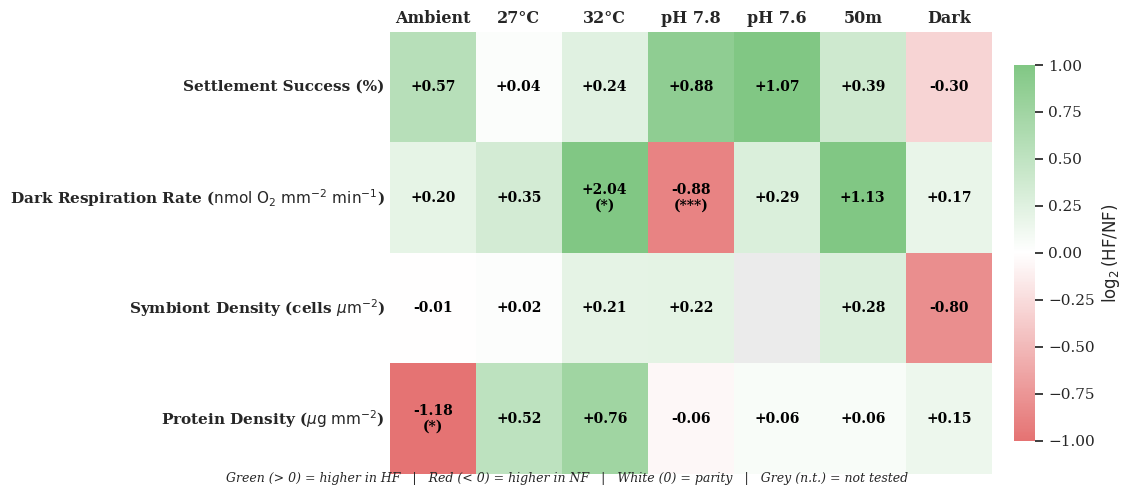

In [91]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from matplotlib.ticker import MultipleLocator

SCALE_MODE = "log2FC"
CORRECTION_LABEL = "BH"
DATA_PATH = Path("Combined_Master_Statistical_Summary.csv")
OUT_STEM = "PhenotypeEffect"
TREATMENT_ORDER = ["Ambient", "27°C", "32°C", "pH 7.8", "pH 7.6", "50m", "Dark"]

TARGET_METRICS = {
    "settlement":       "Settlement Success (%)",
    "respiration":      r"Dark Respiration Rate ($\mathrm{nmol}\ \mathrm{O}_2\ \mathrm{mm}^{-2}\ \mathrm{min}^{-1}$)",
    "symbiont_density": r"Symbiont Density (cells $\mu\mathrm{m}^{-2}$)",
    "protein_density":  r"Protein Density ($\mu\mathrm{g}\ \mathrm{mm}^{-2}$)"
}

CMAP = LinearSegmentedColormap.from_list("morph_advantage", ["#e57373", "#ffffff", "#81c784"], N=256)

def render_heatmap_final():
    summary_df = pd.read_csv(DATA_PATH)

    vals = pd.DataFrame(index=list(TARGET_METRICS), columns=TREATMENT_ORDER, dtype=float)
    annot = pd.DataFrame(index=list(TARGET_METRICS), columns=TREATMENT_ORDER, dtype=object)

    # Generate manual matrices matching baseline
    for m in TARGET_METRICS:
        for c in TREATMENT_ORDER:
            row_match = summary_df[(summary_df['Metric / Parameter'].str.contains(m[:4], case=False)) &
                                   (summary_df['Condition / Treatment'] == c)]
            if row_match.empty or row_match.iloc[0]['Significance'] == 'n.t.':
                vals.loc[m, c] = np.nan
                annot.loc[m, c] = "n.t."
                continue

            hf_str, nf_str = row_match.iloc[0]['HF_Summary'], row_match.iloc[0]['NF_Summary']
            try:
                m_hf = float(hf_str.split(' ')[0])
                m_nf = float(nf_str.split(' ')[0])
                if m_hf <= 0 or m_nf <= 0:
                    val = np.nan
                else:
                    val = np.log2(m_hf / m_nf)
                vals.loc[m, c] = val
                sig_marker = row_match.iloc[0]['Significance']
                sig_suffix = f"\n({sig_marker})" if sig_marker in ['*', '**', '***'] else ""
                annot.loc[m, c] = f"{val:+.2f}{sig_suffix}"
            except:
                vals.loc[m, c] = np.nan
                annot.loc[m, c] = "n.t."

    fig, ax = plt.subplots(figsize=(11.5, 5.0))
    plot_vals = vals.copy()
    plot_vals.index = [TARGET_METRICS[m] for m in plot_vals.index]

    sns.heatmap(
        plot_vals.astype(float),
        annot=annot.values,
        fmt="",
        cmap=CMAP,
        vmin=-1.0,
        vmax=1.0,
        mask=~np.isfinite(plot_vals.astype(float)),
        annot_kws={"size": 10, "weight": "bold", "color": "black"},
        cbar_kws={"label": r"$\log_2(\mathrm{HF}/\mathrm{NF})$", "shrink": 0.85, "aspect": 18, "pad": 0.03},
        ax=ax
    )

    for i in range(len(plot_vals.index)):
        for j in range(len(TREATMENT_ORDER)):
            if not np.isfinite(plot_vals.iloc[i, j]):
                ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor="0.92", edgecolor="white", linewidth=0))

    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xticklabels(TREATMENT_ORDER, rotation=0, ha="center", fontsize=11.5, fontweight="bold")
    ax.set_yticklabels(plot_vals.index, rotation=0, ha="right", fontsize=11, fontweight="bold")
    ax.tick_params(axis="both", which="both", length=0)

    key = "Green (> 0) = higher in HF   |   Red (< 0) = higher in NF   |   White (0) = parity   |   Grey (n.t.) = not tested"
    plt.gcf().text(0.5, 0.02, key, ha="center", fontsize=9, style="italic")
    plt.tight_layout()
    plt.savefig(f"{OUT_STEM}.png", bbox_inches="tight", dpi=600)
    plt.show()

render_heatmap_final()